In [ ]:
from google.colab import files
uploaded = files.upload()

Saving Online_Retail_CSV.csv to Online_Retail_CSV.csv


In [ ]:
import pandas as pd
df = pd.read_csv("Online_Retail_CSV.csv" , sep = ";", encoding="ISO-8859-1")

In [ ]:
df.columns = df.columns.str.strip()
df.head()

,ï»¿InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,"2,55",17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,"2,75",17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom


In [ ]:
df.info()
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   ï»¿InvoiceNo  541909 non-null  object 
 1   StockCode     541909 non-null  object 
 2   Description   540455 non-null  object 
 3   Quantity      541909 non-null  int64  
 4   InvoiceDate   541909 non-null  object 
 5   UnitPrice     541909 non-null  object 
 6   CustomerID    406829 non-null  float64
 7   Country       541909 non-null  object 
dtypes: float64(1), int64(1), object(6)
memory usage: 33.1+ MB
['ï»¿InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [ ]:
total_rows = len(df)

# Rename the column 'ï»¿InvoiceNo' to 'InvoiceNo' if it exists
if 'ï»¿InvoiceNo' in df.columns:
    df.rename(columns={'ï»¿InvoiceNo': 'InvoiceNo'}, inplace=True)

print("="*60)
print("📊 STATISTIQUES DESCRIPTIVES")
print("="*60)

print(f"Transactions totales  : {total_rows:,}")
print(f"Clients distincts     : {df['CustomerID'].nunique():,}")
print(f"Factures distinctes   : {df['InvoiceNo'].nunique():,}")
print(f"Produits distincts    : {df['StockCode'].nunique():,}")
print(f"Pays                  : {df['Country'].nunique():,}")

df[["Quantity","UnitPrice"]].describe()

📊 STATISTIQUES DESCRIPTIVES
Transactions totales  : 541,909
Clients distincts     : 4,372
Factures distinctes   : 25,900
Produits distincts    : 4,070
Pays                  : 38


,Quantity
count,541909.000000
mean,9.552250
std,218.081158
min,-80995.000000
25%,1.000000
50%,3.000000
75%,10.000000
max,80995.000000


In [ ]:
df.isnull().sum()

,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [ ]:
(df.isnull().sum() / len(df)) * 100

,0
InvoiceNo,0.000000
StockCode,0.000000
Description,0.268311
Quantity,0.000000
InvoiceDate,0.000000
UnitPrice,0.000000
CustomerID,24.926694
Country,0.000000


In [ ]:
import pandas as pd

df = pd.read_csv(
    "Online_Retail_CSV.csv",
    encoding="ISO-8859-1",
    sep = ';', # Changed separator from ',' to ';'
    dtype={"UnitPrice": "string"}
)

# nettoyer noms colonnes (BOM + espaces)
df.columns = df.columns.str.strip().str.replace("ï»¿", "", regex=False)

print("Lignes:", len(df))
print(df.dtypes)
df.head()

Lignes: 541909
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate            object
UnitPrice      string[python]
CustomerID            float64
Country                object
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,01/12/2010 08:26,"2,55",17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,01/12/2010 08:26,"2,75",17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,01/12/2010 08:26,"3,39",17850.0,United Kingdom


In [ ]:
import pandas as pd

df["UnitPrice"] = (
  df["UnitPrice"]
    .astype("string")
    .str.strip()
    .str.replace(",", ".", regex=False)
)

df["UnitPrice"] = pd.to_numeric(df["UnitPrice"], errors="coerce")

In [ ]:
print(df.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')


In [ ]:
print("NaN UnitPrice:", df["UnitPrice"].isna().sum())
print("UnitPrice > 0:", (df["UnitPrice"] > 0).sum())
df["UnitPrice"].describe()

NaN UnitPrice: 0
UnitPrice > 0: 539392


,UnitPrice
count,541909.0
mean,4.611114
std,96.759853
min,-11062.06
25%,1.25
50%,2.08
75%,4.13
max,38970.0


In [ ]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], dayfirst=True, errors="coerce")

In [ ]:
print(df.columns)
print(len(df))

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='object')
541909


In [ ]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)

In [ ]:
df_clean = df.loc[
    df["CustomerID"].notna()
    & (df["Quantity"] > 0)
    & (df["UnitPrice"] > 0)
    & (~df["InvoiceNo"].str.startswith("C"))
].copy()

df_clean["CustomerID"] = df_clean["CustomerID"].astype(int)
df_clean["TotalPrice"] = (df_clean["Quantity"] * df_clean["UnitPrice"]).round(2)

print(f"✅ Avant : {len(df):,} → Après : {len(df_clean):,} (supprimé {len(df)-len(df_clean):,})")

df_clean.head()

✅ Avant : 541,909 → Après : 397,884 (supprimé 144,025)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.3
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


# Partie 2 : Segmentation client (Non supervisé)
## Création de variables RFM (Recency, Frequency, Monetary)


## Création de la variable et colonne Recency





La variable **Recency** mesure le nombre de jours écoulés depuis la dernière commande effectuée par chaque client. Elle permet d’identifier les clients ayant acheté récemment et ceux dont la dernière transaction est plus ancienne.

Pour la calculer, nous avons d’abord identifié la **dernière date de transaction du dataset** à partir de la variable `InvoiceDate`. Une **date de référence (`ref_date`)** a ensuite été définie comme un jour après cette dernière transaction afin de servir de point de comparaison.

Les données ont ensuite été **regroupées par client (`CustomerID`)** afin d’identifier la date de la dernière commande pour chacun d’eux. La variable **Recency** est alors obtenue en calculant la **différence, en nombre de jours, entre la date de référence et la dernière transaction de chaque client**.

Une **valeur de Recency faible** indique qu’un client a acheté récemment, tandis qu’une **valeur élevée** signifie que sa dernière commande est plus ancienne.

In [ ]:
import pandas as pd
from datetime import timedelta

# Dernière date du dataset
last_date = df_clean["InvoiceDate"].max()

# 1 jour après la dernière commande
ref_date = last_date + timedelta(days=1)

# Calcul Recency
recency = df_clean.groupby("CustomerID")["InvoiceDate"].max().reset_index()

recency["Recency"] = (ref_date - recency["InvoiceDate"]).dt.days

print(recency.head())

   CustomerID         InvoiceDate  Recency
0       12346 2011-01-18 10:01:00      326
1       12347 2011-12-07 15:52:00        2
2       12348 2011-09-25 13:13:00       75
3       12349 2011-11-21 09:51:00       19
4       12350 2011-02-02 16:01:00      310


# Création de la variable et de la colonne Frequency




La variable **Frequency** mesure le **nombre total de commandes effectuées par chaque client**. Dans l’analyse RFM, cette variable permet d’identifier les clients qui réalisent des achats **occasionnels** ou **réguliers**.

Pour la calculer, nous avons utilisé la variable `InvoiceNo`, qui correspond au **numéro de facture associé à chaque commande**. Les données ont été **regroupées par client (`CustomerID`)** à l’aide de la fonction `groupby()`, puis la fonction `nunique()` a été utilisée afin de **compter le nombre de factures distinctes pour chaque client**. Cela permet ainsi d’obtenir le **nombre total de commandes réalisées par client**.

Les premiers résultats montrent par exemple que le client **12346** a effectué **1 commande**, tandis que le client **12347** en a effectué **7** et le client **12348** en a réalisé **4**.

Une analyse descriptive globale a également été réalisée afin de mieux comprendre la structure des données. Le dataset nettoyé contient **397 884 lignes de transactions**, correspondant à **18 532 commandes distinctes**. Après agrégation par client, le nombre total de commandes comptabilisées dans la variable **Frequency** est également de **18 532**, avec une moyenne d’environ **4 commandes par client**.

Enfin, une vérification a été effectuée afin de s’assurer que la **colonne `Frequency` a bien été créée dans le DataFrame**.

In [ ]:
# Création de la variable Frequency : nombre de commandes par client

frequency = df_clean.groupby("CustomerID")["InvoiceNo"].nunique().reset_index()

frequency.columns = ["CustomerID","Frequency"]

print(frequency.head())
# Agrégation globale
print("total_lignes :", len(df_clean))
print("Nbr_commandes :", df_clean["InvoiceNo"].nunique())
print("Total_commandes :", frequency["Frequency"].sum())
print("Nbr_moyen_commande :", frequency["Frequency"].mean())

   CustomerID  Frequency
0       12346          1
1       12347          7
2       12348          4
3       12349          1
4       12350          1
total_lignes : 397884
Nbr_commandes : 18532
Total_commandes : 18532
Nbr_moyen_commande : 4.272014753342554


# Création de la variable et de la colonne "Monetary"





La variable **Monetary** permet de mesurer le **montant total dépensé par chaque client**. Pour la calculer, nous avons utilisé la variable `TotalPrice`, obtenue en multipliant le **prix unitaire (`UnitPrice`)** par la **quantité achetée (`Quantity`)** pour chaque transaction.

Ensuite, afin d’obtenir le **montant total dépensé par client**, les données ont été **regroupées par identifiant client (`CustomerID`)** à l’aide de la fonction `groupby()`. La **somme des montants de chaque transaction** a ensuite été calculée pour chaque client, ce qui permet d’obtenir la **dépense totale associée à chaque client**.

La colonne obtenue a ensuite été **renommée `Monetary`** afin d’être utilisée dans l’analyse **RFM**.

Une **vérification finale** a ensuite été réalisée en affichant les **premières lignes du DataFrame**, ce qui permet de confirmer que la variable **`Monetary` a bien été calculée et ajoutée aux données**.

In [ ]:
# Convertir type de la variable UnitPrice en numérique => Float
print(df_clean["UnitPrice"].head(5))
df_clean["UnitPrice"] = df_clean["UnitPrice"].astype(float)
# Création de la variable Monetary désignant le total dépensé par le client

df_clean["Monetary"] = df_clean["UnitPrice"] * df_clean["Quantity"]

monetary = df_clean.groupby("CustomerID")["Monetary"].sum().reset_index()

# Vérification
print(df_clean[["CustomerID", "UnitPrice", "Quantity", "Monetary"]].head(5).to_string(index=False))

# Vérification colonne afin de confirmer la création de la variable Monetary
df_clean.columns

0    2.55
1    3.39
2    2.75
3    3.39
4    3.39
Name: UnitPrice, dtype: Float64
 CustomerID  UnitPrice  Quantity  Monetary
      17850       2.55         6     15.30
      17850       3.39         6     20.34
      17850       2.75         8     22.00
      17850       3.39         6     20.34
      17850       3.39         6     20.34


Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country', 'TotalPrice', 'Monetary'],
      dtype='object')

# Regroupement des variables RFM dans un seul DataFrame


## Création du DataFrame RFM

Après la création des variables **Recency**, **Frequency** et **Monetary**, celles-ci ont été regroupées dans un seul DataFrame afin de préparer les données pour l’analyse de segmentation.

Pour cela, les trois tables ont été **fusionnées à l’aide de la fonction `merge()`** en utilisant la variable **`CustomerID` comme clé commune**. Dans un premier temps, les variables **Recency** et **Frequency** ont été fusionnées, puis la variable **Monetary** a été ajoutée dans un second temps. Cette étape permet d’obtenir, pour chaque client, **l’ensemble des indicateurs RFM dans une même structure de données**.

Les **valeurs manquantes** ont ensuite été supprimées à l’aide de la fonction `dropna()` afin de conserver uniquement les clients pour lesquels **les trois variables sont disponibles**.

Le DataFrame obtenu contient ainsi **un enregistrement par client**, avec les variables **Recency**, **Frequency** et **Monetary**, qui seront utilisées dans les étapes suivantes de **l’analyse de segmentation**.

Un aperçu des **premières lignes du DataFrame** permet de vérifier que les variables ont bien été regroupées et que chaque client est désormais associé à **ses trois indicateurs RFM**.

In [ ]:
rfm = recency.merge(frequency, on="CustomerID")
rfm = rfm.merge(monetary, on="CustomerID")
rfm = rfm.dropna()
print(rfm.head(10).to_string(index=False))

 CustomerID         InvoiceDate  Recency  Frequency  Monetary
      12346 2011-01-18 10:01:00      326          1  77183.60
      12347 2011-12-07 15:52:00        2          7   4310.00
      12348 2011-09-25 13:13:00       75          4   1797.24
      12349 2011-11-21 09:51:00       19          1   1757.55
      12350 2011-02-02 16:01:00      310          1    334.40
      12352 2011-11-03 14:37:00       36          8   2506.04
      12353 2011-05-19 17:47:00      204          1     89.00
      12354 2011-04-21 13:11:00      232          1   1079.40
      12355 2011-05-09 13:49:00      214          1    459.40
      12356 2011-11-17 08:40:00       23          3   2811.43


# Assemblage des variables RFM





Afin de préparer les données pour l’application des **algorithmes de machine learning**, les variables **Recency**, **Frequency** et **Monetary** ont été regroupées sous forme de **vecteur de variables explicatives**.

Pour cela, les trois colonnes `Recency`, `Frequency` et `Monetary` ont d’abord été **sélectionnées à partir du DataFrame `rfm`**. Une nouvelle colonne appelée **`features`** a ensuite été créée afin de **regrouper ces trois variables dans une seule structure**, sous forme de **liste de valeurs pour chaque client**.

Cette étape permet de **représenter chaque client par un vecteur contenant ses indicateurs RFM**, ce qui est nécessaire pour appliquer des méthodes de segmentation telles que **les algorithmes de clustering**.

Une **vérification** a ensuite été effectuée en affichant les **premières lignes de la colonne `features`**, ce qui permet de confirmer que chaque client est désormais **représenté par un vecteur contenant ses valeurs Recency, Frequency et Monetary**.

In [ ]:
#####  Assemblement dans un même dataset ces 3 éléments => Recency, Monetary, Frequency

# Assemblage des features
features = rfm[['Recency', 'Frequency', 'Monetary']]

# Création d'une colonne "features" contenant les trois variables sous forme de vecteur
rfm["features"] = features.values.tolist()

# Vérification
print(rfm[["features"]].head())

                features
0  [326.0, 1.0, 77183.6]
1     [2.0, 7.0, 4310.0]
2   [75.0, 4.0, 1797.24]
3   [19.0, 1.0, 1757.55]
4    [310.0, 1.0, 334.4]


# Normalisation des variables RFM avec StandardScaler







Avant d’appliquer l’algorithme de **clustering**, les variables **Recency**, **Frequency** et **Monetary** ont été **normalisées afin de les rendre comparables**. En effet, ces variables sont exprimées dans des **échelles très différentes** : `Recency` correspond à un **nombre de jours**, `Frequency` à un **nombre de commandes**, tandis que `Monetary` représente un **montant dépensé**. Sans normalisation, les variables ayant les **valeurs les plus élevées pourraient influencer excessivement le modèle**.

Pour résoudre ce problème, nous avons utilisé la méthode **`StandardScaler`**, qui permet de **standardiser les variables** en transformant les données de manière à obtenir une **moyenne proche de 0** et un **écart-type égal à 1**.

Le **scaler** est d’abord créé à l’aide de `StandardScaler()`, puis appliqué aux variables **`Recency`**, **`Frequency`** et **`Monetary`** grâce à la fonction `fit_transform()`, qui réalise à la fois **l’apprentissage des paramètres de normalisation et la transformation des données**.

Les variables **RFM** sont ainsi **mises à la même échelle avant d’être utilisées dans l’algorithme de clustering**.

In [ ]:

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled = scaler.fit_transform(rfm[['Recency','Frequency','Monetary']])

print(scaled[:5])

[[ 2.33457414 -0.4250965   8.35866818]
 [-0.90534032  0.3544168   0.25096626]
 [-0.17535959 -0.03533985 -0.02859601]
 [-0.73534481 -0.4250965  -0.0330118 ]
 [ 2.17457836 -0.4250965  -0.19134727]]


# Clustering avec Bisecting Kmeans


Afin d’identifier des groupes de clients présentant des **comportements d’achat similaires**, nous avons appliqué une **méthode de clustering non supervisé** basée sur l’algorithme **Bisecting K-Means**. Cet algorithme est une **variante du K-Means classique**, mais il adopte une **approche hiérarchique divisive**.

Contrairement au **K-Means traditionnel** qui partitionne directement les données en **K groupes**, le **Bisecting K-Means** commence par considérer **l’ensemble des données comme un seul cluster**, puis le **divise progressivement en sous-groupes successifs** à l’aide de **K-Means (avec K = 2)** jusqu’à obtenir le **nombre de clusters souhaité**. Cette approche permet généralement d’obtenir **des clusters plus homogènes et plus stables**, car elle est **moins sensible au choix initial des centroïdes**.

Le modèle a été implémenté à l’aide de la bibliothèque utilisée pour le clustering, en fixant le **nombre de clusters à 3 (`n_clusters = 3`)**. Le modèle est ensuite entraîné sur les **données normalisées contenant les variables `Recency`, `Frequency` et `Monetary`** grâce à la méthode `fit_predict()`, qui permet à la fois **d’apprendre la structure des données et d’attribuer un cluster à chaque client**.

Les **étiquettes de cluster obtenues** ont ensuite été ajoutées au **DataFrame `rfm`** dans une nouvelle colonne appelée **`cluster`**, permettant ainsi **d’identifier le groupe auquel appartient chaque client**.

Afin d’évaluer la **qualité de la segmentation obtenue**, nous avons utilisé le **Silhouette Score**, une métrique qui mesure **la cohésion et la séparation entre les clusters**. Le score obtenu est de **0.593**, ce qui indique **une séparation modérée mais satisfaisante des groupes de clients**.

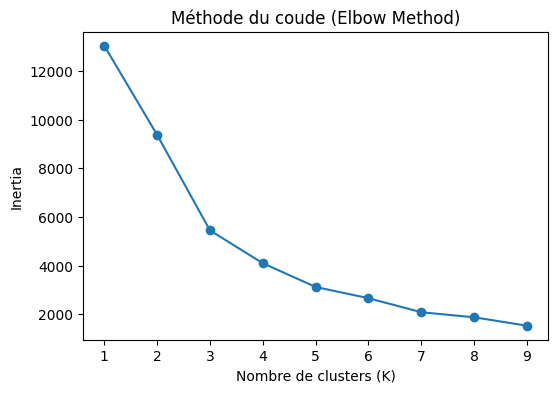

In [ ]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

inertia = []
k_range = range(1,10)

for k in k_range:
    model = KMeans(n_clusters=k, random_state=42)
    model.fit(scaled)
    inertia.append(model.inertia_)

plt.figure(figsize=(6,4))
plt.plot(k_range, inertia, marker='o')
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertia")
plt.title("Méthode du coude (Elbow Method)")
plt.show()

In [ ]:
from sklearn.cluster import BisectingKMeans
from sklearn.metrics import silhouette_score

model = BisectingKMeans(n_clusters=3, random_state=42)

labels = model.fit_predict(scaled)

rfm["cluster"] = labels

print("Silhouette Score:", silhouette_score(scaled, labels))

print("Centroids :")
print(model.cluster_centers_)

Silhouette Score: 0.5912501367079358
Centroids :
[[-0.51900657  0.05595069 -0.01918125]
 [-0.8647484   8.07913332  9.33691287]
 [ 1.51649794 -0.35038016 -0.1630249 ]]


In [ ]:
print(df.shape)
print(rfm.shape)

(541909, 8)
(4346, 8)



Ce bloc applique un algorithme de **clustering (Bisecting KMeans)** sur les données RFM normalisées et analyse les segments obtenus :

1. **Assignation des clients aux clusters**  
   - `model.predict(scaled)` permet d’assigner chaque client à un **cluster** en fonction de son profil RFM.  
   - `rfm["cluster"] = model.predict(scaled)` ajoute la colonne `"cluster"` dans le DataFrame `rfm`, indiquant le segment auquel appartient chaque client.  
   - `rfm[["CustomerID", "cluster"]].head(100)` affiche les **100 premiers clients avec leur cluster** afin de vérifier l’attribution.

2. **Centroïdes des clusters**  
   - `model.cluster_centers_` affiche les **centroïdes des clusters**.  
   - Chaque centroïde représente le **profil moyen d’un segment de clients** selon les variables Recency, Frequency et Monetary.

3. **Analyse des segments**  
   - `rfm.groupby("cluster")[["Recency", "Frequency", "Monetary"]].mean()` permet de calculer la **moyenne des variables RFM pour chaque cluster**.  
   - `print(cluster_summary)` affiche ces moyennes afin de **comparer les différents segments de clients**.

➡ Cette étape permet d’identifier **des groupes de clients aux comportements d’achat similaires** et d’analyser leur niveau d’activité, leur fréquence d’achat et leur valeur financière afin d’adapter les stratégies marketing ou commerciales.

In [ ]:
# Obtenir les centroïdes et assigner chaque client à un cluster

# Assigner chaque client à un cluster
rfm["cluster"] = model.predict(scaled)

# Afficher 100 clients avec leur cluster
print(rfm[["CustomerID", "cluster"]].head(20).to_string(index=False))

# Afficher les centroïdes de tous les clusters
print("Centroids :")
print(model.cluster_centers_)

# Analyser les segments
# Calculer la moyenne des features par cluster
cluster_summary = rfm.groupby("cluster")[["Recency", "Frequency", "Monetary"]].mean()

# Permet l'affichage des moyennes de l'ensemble des variables par leurs clusters
print(cluster_summary)

 CustomerID  cluster
      12346        2
      12347        0
      12348        0
      12349        0
      12350        2
      12352        0
      12353        2
      12354        2
      12355        2
      12356        0
      12357        0
      12358        0
      12359        0
      12360        0
      12361        2
      12362        0
      12363        0
      12364        0
      12365        2
      12367        0
Centroids :
[[-0.51900657  0.05595069 -0.01918125]
 [-0.8647484   8.07913332  9.33691287]
 [ 1.51649794 -0.35038016 -0.1630249 ]]
            Recency  Frequency      Monetary
cluster                                     
0         40.590399   4.706047   1883.831915
1          6.038462  66.423077  85904.351538
2        244.109712   1.580935    592.536647


In [ ]:
rfm["cluster"].value_counts()

,count
cluster,
0,3208
2,1112
1,26


## Interprétation des clusters

**Cluster 0 :** clients ayant une **récence élevée (≈246 jours)**, une **faible fréquence d’achat (≈1,6 commandes)** et une **dépense relativement faible (≈631)**. Ce groupe comprend **1089 clients** et correspond à des **clients peu actifs ou potentiellement inactifs**.

**Cluster 1 :** clients présentant une **récence modérée (≈41 jours)**, une **fréquence d’achat moyenne (≈4,7 commandes)** et un **niveau de dépense intermédiaire (≈1859)**. Ce groupe représente la **majorité des clients (3223 clients)** et correspond à des **clients relativement actifs**

**Cluster 2 :** clients caractérisés par une **récence très faible (≈6 jours)**, une **fréquence d’achat très élevée (≈66 commandes)** et un **niveau de dépense très important (≈85 904)**. Ce segment est **très restreint**, mais correspond aux **clients les plus fidèles et les plus rentables**.

Cette segmentation permet ainsi **d’identifier des groupes de clients aux comportements distincts**, ce qui peut aider l’entreprise à **adapter ses stratégies marketing**, par exemple en **fidélisant les clients à forte valeur** ou en **réactivant les clients moins actifs**.


# Visualisation graphique: Etude comportementale et économique des agents




In [ ]:
# Importation de matplotlib.pyplot
# Cette bibliothèque permet de créer des graphiques et des visualisations de données
import matplotlib.pyplot as plt

# Importation de seaborn
# Seaborn est une bibliothèque de visualisation basée sur matplotlib
# Elle permet de produire des graphiques statistiques plus lisibles et esthétiques
import seaborn as sns


# Exécution du One-Hot Encoder

Cette étape consiste à transformer la variable catégorielle **Country** en **variables numériques binaires** pour pouvoir l’utiliser dans des modèles de machine learning. Ainsi, chaque pays devient une colonne distincte.

On obtient donc pour chaque observation, la colonne correspondant au pays concerné est 1, les autres sont 0.

Cette transformation permet de représenter les pays de façon que les algorithmes puissent les traiter mathématiquement sans introduire d’ordre implicite.

In [ ]:
# Execution du hot encoder

from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder()
encoded = encoder.fit_transform(df[['Country']]).toarray()
print(encoded)


[[0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 [0. 0. 0. ... 0. 1. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


In [ ]:
# Créer un DataFrame avec les noms de colonnes
encoded_df = pd.DataFrame(encoded, columns=encoder.get_feature_names_out(['Country']))

print(encoded_df)



        Country_Australia  Country_Austria  Country_Bahrain  Country_Belgium  \
0                     0.0              0.0              0.0              0.0   
1                     0.0              0.0              0.0              0.0   
2                     0.0              0.0              0.0              0.0   
3                     0.0              0.0              0.0              0.0   
4                     0.0              0.0              0.0              0.0   
...                   ...              ...              ...              ...   
541904                0.0              0.0              0.0              0.0   
541905                0.0              0.0              0.0              0.0   
541906                0.0              0.0              0.0              0.0   
541907                0.0              0.0              0.0              0.0   
541908                0.0              0.0              0.0              0.0   

        Country_Brazil  Country_Canada 

# Visualisation de la relation entre Quantity et Country

Cette visualisation montre comment les quantités achetées (Quantity) se répartissent selon les pays (Country).

Afin de procéder à sa réalisation nous avons effectués les étapes précédents.

- Nettoyage des données : seules les quantités positives et inférieures au 99ᵉ percentile sont conservées pour éviter les valeurs extrêmes qui fausseraient le graphique.

- Importance : la quantité est transformée en logarithme pour réduire l’effet des valeurs très grandes. Ensuite, on calcule une mesure d’importance basée sur la proximité à la moyenne.

Ensuite, nous avons effectué la préparation des axes où chaque pays sont convertis en valeurs numériques pour l’axe X.

Ainsi, au sein de notre graphique nous avons déterminé:

- Axe X : pays

- Axe Y : quantité (échelle logarithmique)

- La variation de couleurs permet de réprésenter l'importance.

Enfin, une transparence des points a été effectué afin de mieux percevoir la densité.

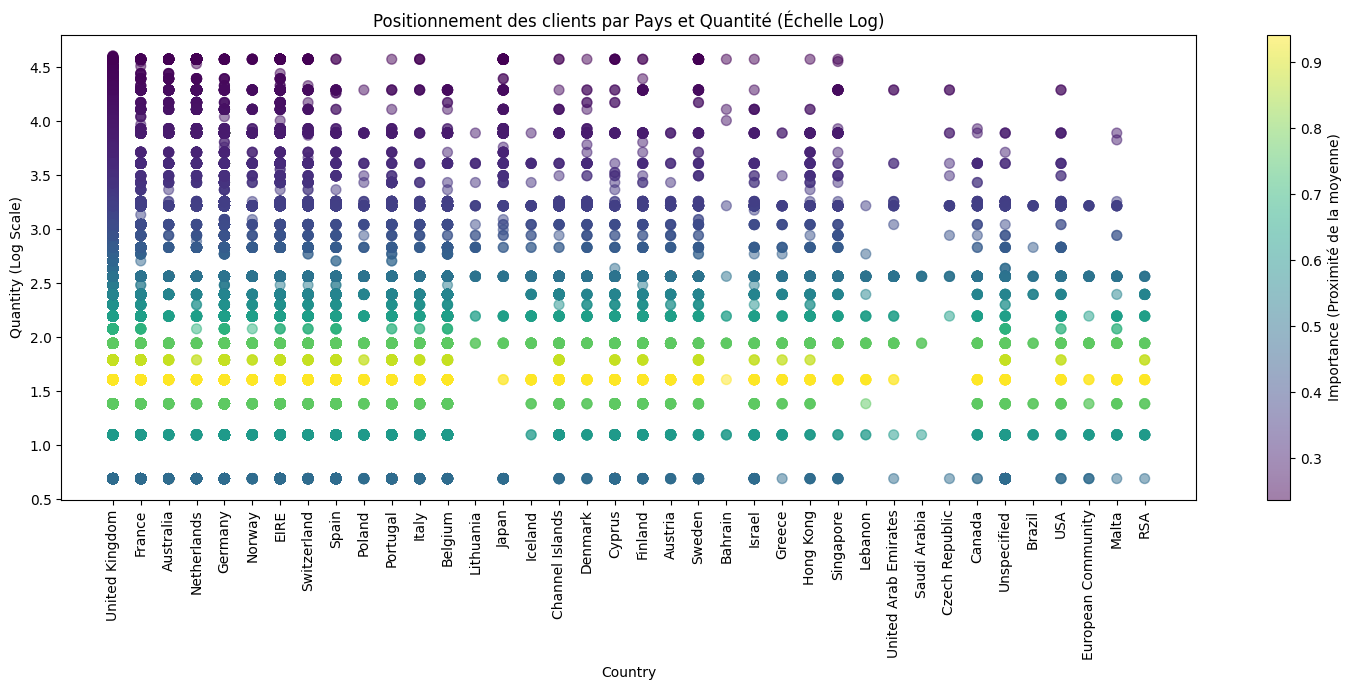

In [ ]:
# Visualisation relation entre Quantity et Country

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Nettoyage strict (on garde les quantités positives raisonnables)
# On filtre les outliers extrêmes (> percentile 99) pour que le graph respire
q_limit = df['Quantity'].quantile(0.99)
df_plot = df[(df['Quantity'] > 0) & (df['Quantity'] < q_limit)].copy()
df_plot = df_plot.dropna(subset=['Quantity', 'Country'])

# 2. Calcul de l'Importance (plus simple et robuste)
# On utilise le log de la quantité pour que l'importance ne soit pas dictée par un seul point
X = df_plot[['Quantity']].copy()
X['Quantity_log'] = np.log1p(X['Quantity'])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X[['Quantity_log']])
center = X_scaled.mean(axis=0)
df_plot['importance'] = 1 / (1 + np.abs(X_scaled - center).flatten())

# 3. Préparation des axes
country_mapping = {country: i for i, country in enumerate(df_plot['Country'].unique())}
df_plot['Country_num'] = df_plot['Country'].map(country_mapping)

# --- LA CORRECTION VISUELLE ---
# Au lieu de normaliser entre 0 et 1, on utilise le LOG direct pour l'axe Y
df_plot['Quantity_log'] = np.log1p(df_plot['Quantity'])

plt.figure(figsize=(15,7))
scatter = plt.scatter(
    df_plot['Country_num'],
    df_plot['Quantity_log'], # On utilise le log ici !
    c=df_plot['importance'],
    cmap='viridis',
    s=50,
    alpha=0.5 # Plus de transparence pour voir la densité
)

plt.xlabel("Country")
plt.ylabel("Quantity (Log Scale)")
plt.title("Positionnement des clients par Pays et Quantité (Échelle Log)")
plt.colorbar(scatter, label='Importance (Proximité de la moyenne)')

# On ne garde que les 15 premiers pays pour la lisibilité si besoin
plt.xticks(list(country_mapping.values()), list(country_mapping.keys()), rotation=90)

plt.tight_layout()
plt.show()



In [ ]:
# Librairie pour le machine learning et le preprocessing
from sklearn.preprocessing import OneHotEncoder  # Permet de convertir des variables catégorielles en variables binaires (0 ou 1)
from sklearn.preprocessing import StandardScaler  # Permet de normaliser/standardiser les données.

#Librairie pour manipuler les tableaux et calculs numériques
import numpy as np  # Permet de travailler avec des tableaux multidimensionnels et des opérations mathématiques rapides

#Librairie pour visualiser les données
import matplotlib.pyplot as plt  # Permet de créer des graphiques et visualisations 2D (courbes, histogrammes, scatter plots…)

# Librairie pour manipuler des données sous forme de tableaux (DataFrames)
import pandas as pd  # Permet de lire, manipuler et analyser facilement des datasets.

#Librairie pour encoder des labels (transformer des catégories en nombres)
from sklearn.preprocessing import LabelEncoder  # Transforme des labels textuels en valeurs numériques pour le ML



# Analyse Prix vs Produits avec Importance

Afin de pouvoir executer ce graphique, nous avons effectué les étapes suivantes:

- **Nettoyage strict** : à travers lequel nous supprimons les prix négatifs et ceux > 500€ pour éviter que des valeurs extrêmes faussent l’analyse.

- **Réalisation d'encodage des produits** dans lequel on transforme StockCode en numérique pour pouvoir le représenter graphiquement.

- **Importance** : on y calcule la proximité de chaque point au centre des données standardisées ( UnitPrice et StockCode).

- **Jitter** : Permet d'effectuer un léger décalage aléatoire ajouté aux indices de produits pour réduire le chevauchement des points.

- **Scatter plot** : cela permet d'effectué la visualisation des prix unitaires et  produits avec couleur représentant l’importance et transparence pour mieux voir la densité.

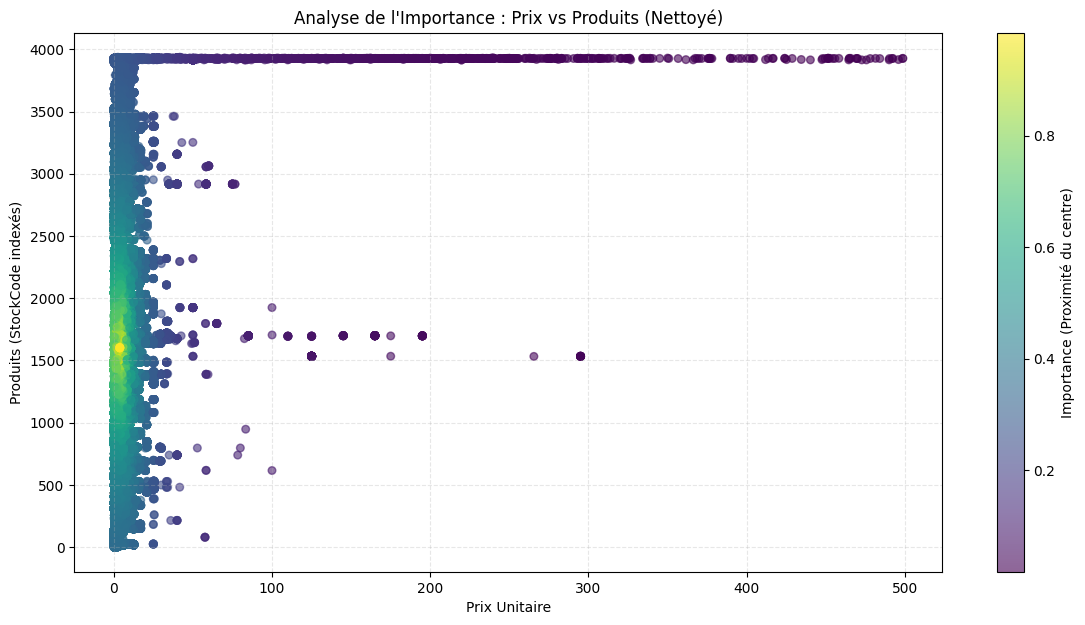

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder

# NETTOYAGE STRICT (Indispensable pour que le calcul d'importance fonctionne)
# On enlève les prix négatifs et les prix délirants qui cassent la moyenne
df_plot = df[['UnitPrice', 'StockCode']].dropna().copy()
df_plot['UnitPrice'] = pd.to_numeric(df_plot['UnitPrice'].astype(str).str.replace(",", "."), errors='coerce')
df_plot = df_plot[(df_plot['UnitPrice'] > 0) & (df_plot['UnitPrice'] < 500)] # On limite à 500€ max
df_plot = df_plot.dropna()

# ENCODAGE
le = LabelEncoder()
df_plot['StockCode_num'] = le.fit_transform(df_plot['StockCode'].astype(str))

# CALCUL DE L'IMPORTANCE (Sur données propres)
X = df_plot[['UnitPrice', 'StockCode_num']].to_numpy()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
center = X_scaled.mean(axis=0)

# Importance basée sur la proximité au centre (plus on est proche de la moyenne, plus l'importance est haute)
df_plot['importance'] = 1 / (1 + np.linalg.norm(X_scaled - center, axis=1))

# JITTER
np.random.seed(42)
df_plot['StockCode_jitter'] = df_plot['StockCode_num'] + np.random.uniform(-0.3, 0.3, size=len(df_plot))

# SCATTER PLOT AVEC ÉCHELLE LOG (Pour mieux voir la distribution des prix)
plt.figure(figsize=(14,7))
scatter = plt.scatter(
    df_plot['UnitPrice'],
    df_plot['StockCode_jitter'],
    c=df_plot['importance'],
    cmap='viridis',
    s=30, # Points un peu plus petits pour moins de chevauchement
    alpha=0.6
)

plt.colorbar(scatter, label='Importance (Proximité du centre)')
plt.xlabel('Prix Unitaire')
plt.ylabel('Produits (StockCode indexés)')
plt.title('Analyse de l\'Importance : Prix vs Produits (Nettoyé)')
plt.grid(True, linestyle='--', alpha=0.3)
plt.show()





# Visualisation des Quantités par Produit

Afin d'afficher le **Top 20 produits** : on se concentre sur les 20 StockCode les plus commandés pour limiter l’encombrement.

On effectue un **Boxplot horizontal** qui nous permet de montre la distribution des quantités commandées pour chaque produit.

Au sein de cette visualisation l'**échelle logarithmique sur X** a été utilisé afin de  mieux visualiser les variations malgré la présence de valeurs extrêmes (outliers).

L'utilisatio  de couleur par produit a été jugé utile afin de facilite l’identification des produits au sein du graphique.

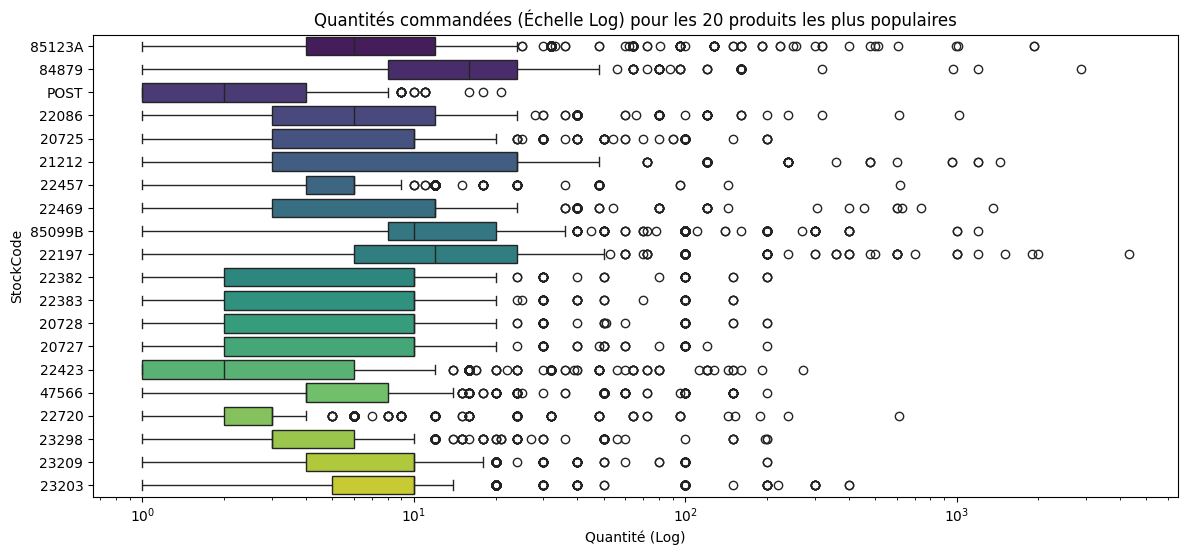

In [ ]:
# Visualisation relation entre la variable Quantity et StockCode
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Top 20 produits (Quantités)
top_products = df_clean['StockCode'].value_counts().head(20).index
df_top = df_clean[df_clean['StockCode'].isin(top_products)].copy()

plt.figure(figsize=(14,6))
# Utilisation de log sur l'axe X pour voir les distributions écrasées par les outliers
sns.boxplot(y='StockCode', x='Quantity', data=df_top, orient='h', hue='StockCode', palette='viridis', legend=False)
plt.xscale('log')
plt.title('Quantités commandées (Échelle Log) pour les 20 produits les plus populaires')
plt.xlabel('Quantité (Log)')
plt.show()




In [ ]:
# Ajout de la variable country au sein du dataframe rfm
rfm = rfm.merge(df[['CustomerID','Country']].drop_duplicates(), on='CustomerID', how='left')



# Boxplot des dépenses par pays

Afin de permettre son execution et son fonctionnement nous avons tout d'abord procédé à un **filtrage** nous permettant d'afficher seulement les dépenses positives où **Monetary > 0** qui seront concervés afin d'éviter les valeurs nulles et négatives.

Ensuite, nous avons effectué les étapes suivantes:

- **Tri** : Ce trie effectué au sein des pays nous a permis de les ordonnés selon la médiane des dépenses, du plus élevé au plus faible.

- **boxplot horizontal** a été executé afin de montrer la distribution des dépenses par client.

- **Utilisation d'une échelle logarithmique**: ce qui nous permet de visualiser les variations même si certaines dépenses sont aberrantes ou extrêmes.

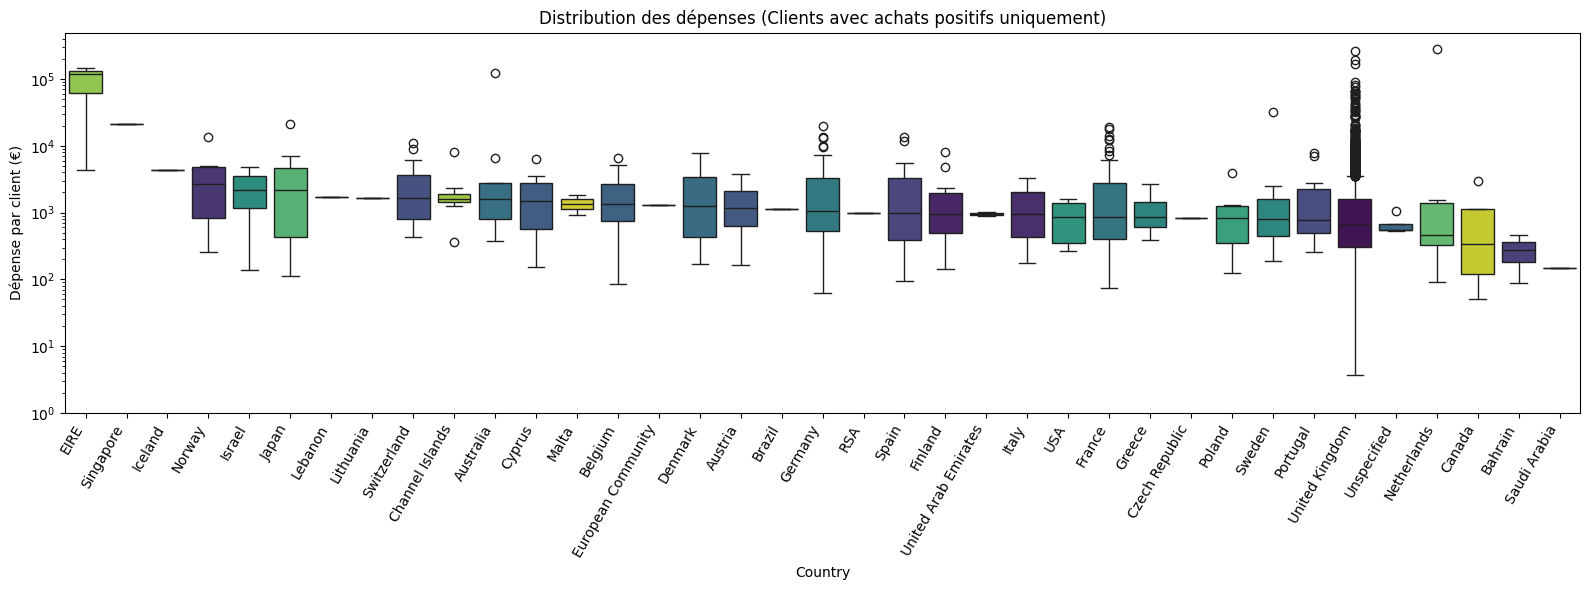

In [ ]:
# Execution de Boxplot
# 1. On effectue un filtrage pour ne garder que les clients qui ont dépensé plus de 0
rfm_clean = rfm[rfm['Monetary'] > 0]

# On refait le graphique avec ces données propres
plt.figure(figsize=(16,6))

# On effectue un recalcule de l'ordre sur les données filtrées
my_order = rfm_clean.groupby("Country")["Monetary"].median().sort_values(ascending=False).index

sns.boxplot(
    x="Country",
    y="Monetary",
    data=rfm_clean, #  On utilise rfm_clean pour lequel on a effectué le filtrage
    order=my_order,
    palette="viridis",
    hue="Country",
    legend=False
)

plt.yscale('log')

# On limite l'axe Y pour ne pas descendre sous 1 (si  des produits à plus de 1€ on était vendu)
plt.ylim(bottom=1)

plt.xticks(rotation=60, ha="right")
plt.ylabel("Dépense par client (€)")
plt.title("Distribution des dépenses (Clients avec achats positifs uniquement)")

plt.tight_layout()
plt.show()





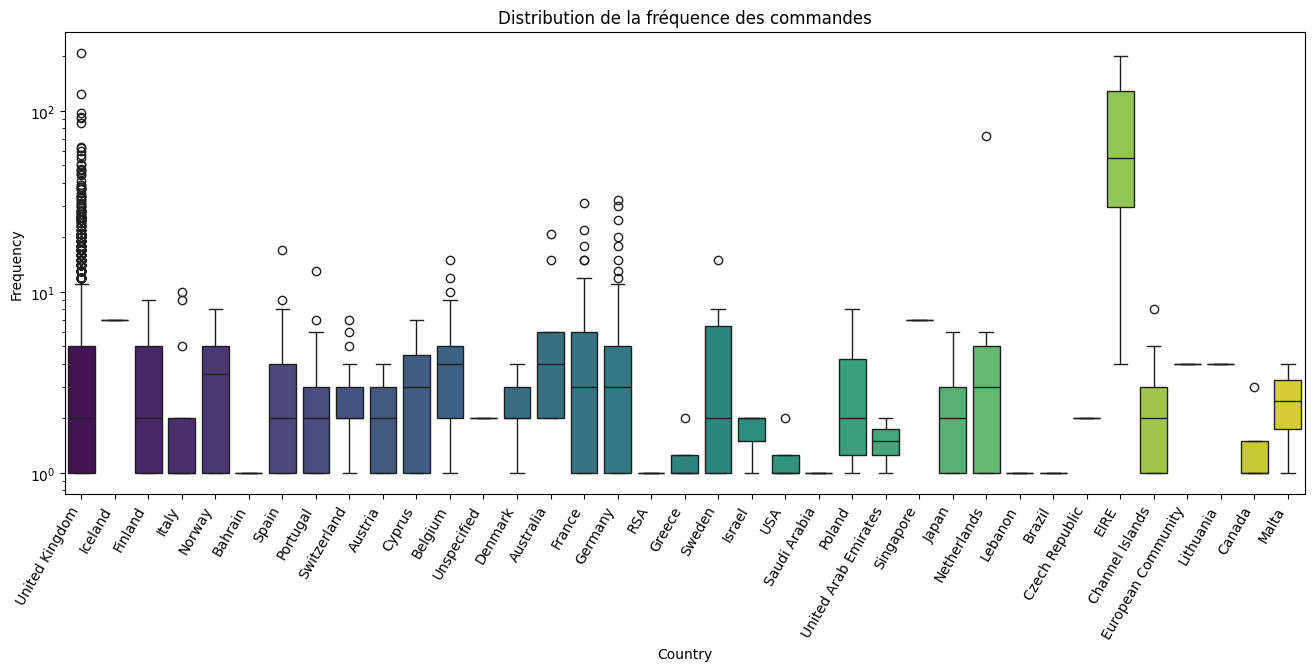

In [ ]:
### Boxplot mettant en relation frequency et la variable Country
plt.figure(figsize=(16,6))

# Filtre simple pour éviter l'erreur de log(0)
rfm_freq = rfm[rfm['Frequency'] > 0]

sns.boxplot(
    x="Country",
    y="Frequency",
    data=rfm_freq,
    palette="viridis",
    hue="Country",
    legend=False
)

plt.yscale('log')

plt.xticks(rotation=60, ha="right")
plt.title("Distribution de la fréquence des commandes")
plt.show()





# Total des revenus par pays

Afin de rendre cette visualisation possible, on effectue ce **principe d'aggrégation** pour lequel on regroupe l'ensemble des données pour venant de chacun des pays et on effectue la sommes de chaque dépenses ( Monetary) pour ainsi obtenir les dépenses total pour chacune d'entre elles.

Un Barplot horizontal est notamment effectué afin de permettre de comparer facilement les revenus totaux entre pays.De plus, un **tri décroissant** pour lequel les pays sont affichés du plus grand au plus petit en fonction de leurs dépenses pour faciliter la lecture.

**Détails**
- Palette viridis : améliore la lisibilité et la distinction visuelle entre les barres.

/tmp/ipykernel_6154/636760137.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


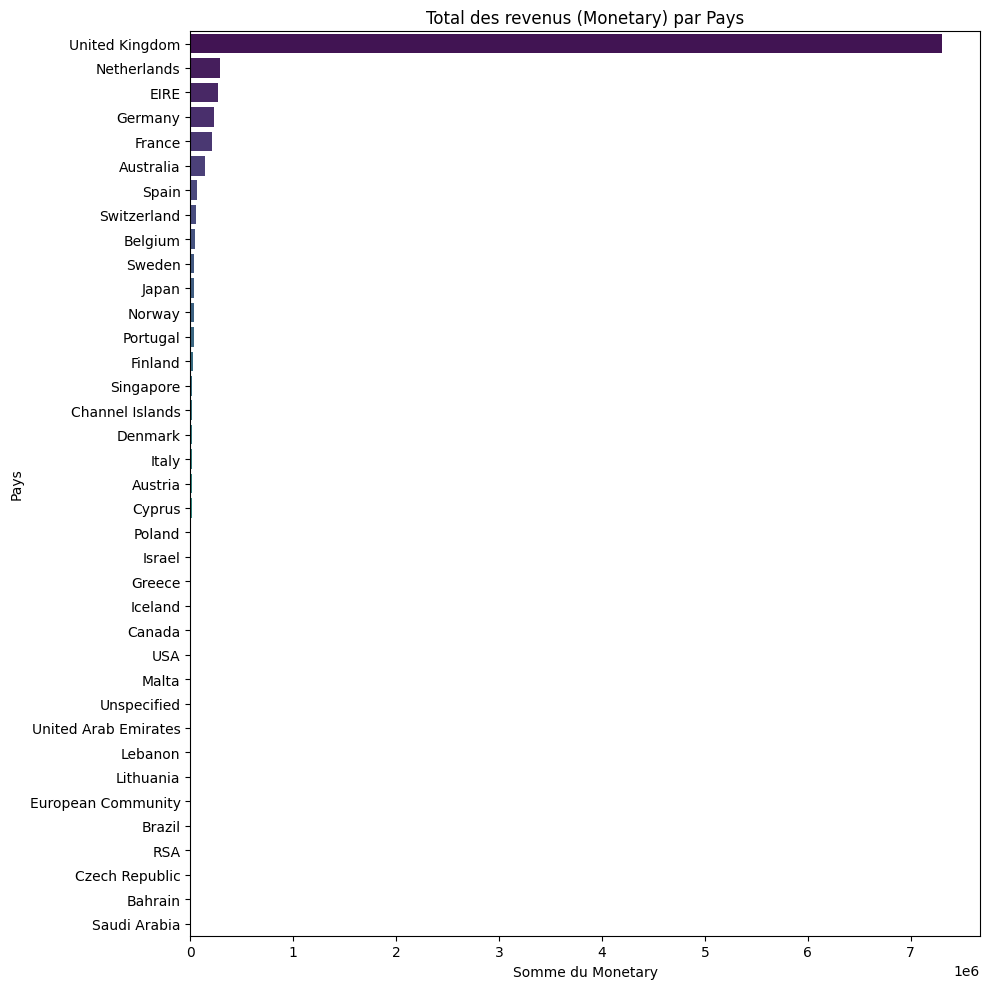

In [ ]:
# On prépare les données en groupant par pays et en sommant le Monetary
data_sorted = rfm.groupby('Country')['Monetary'].sum().sort_values(ascending=False).reset_index()


plt.figure(figsize=(10, 10)) # Permet ainsi de lire tous les pays
sns.barplot(
    x="Monetary",
    y="Country",
    data=data_sorted,
    palette="viridis"
)

plt.title("Total des revenus (Monetary) par Pays")
plt.xlabel("Somme du Monetary")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()




In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. On crée rfm_no_uk en excluant le Royaume-Uni
rfm_no_uk = rfm_clean[rfm_clean['Country'] != 'United Kingdom'].copy()  # ou 'UK' selon le nom exact

# 2. On sélectionne les 15 premiers pays par dépense totale
top15_no_uk = rfm_no_uk.groupby("Country")["Monetary"].sum().sort_values(ascending=False).head(15).reset_index()




/tmp/ipykernel_6154/3684478223.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


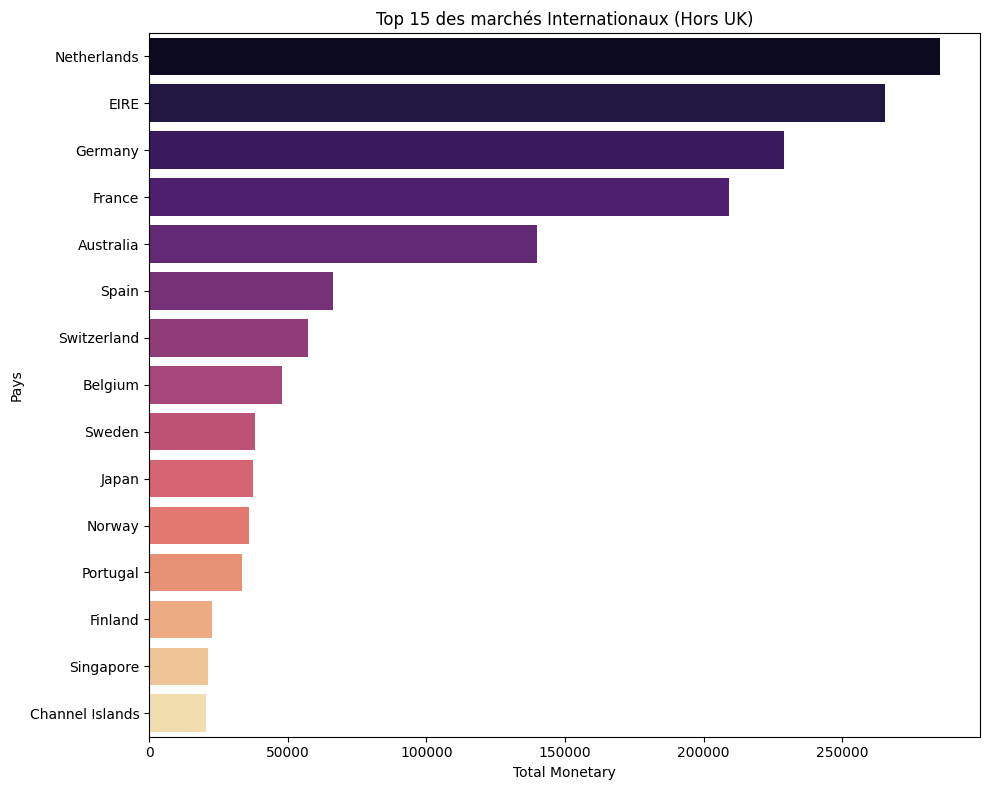

In [ ]:
# On effectue une analyse plus pouser en effectuant un zoom sur l'ensemble des autres pays tout en excluant les valeurs de UK qui sont largement dominante.
# Création du barplot

plt.figure(figsize=(10, 8))
sns.barplot(
    x="Monetary",
    y="Country",
    data=top15_no_uk,
    palette="magma"  # couleur uniforme
)

plt.title("Top 15 des marchés Internationaux (Hors UK)")
plt.xlabel("Total Monetary")
plt.ylabel("Pays")
plt.tight_layout()
plt.show()





# Histogramme du nombre de commandes par pays

Afin d'optimiser la visualisation de la répartition des commandes selon les pays, nous avons donc jugée utile l'ensemble de ces étapes:

- **Countplot avec hue** : permettant à ce que chaque pays puisse avoir leur propre couleur, nous permettant aini de faciliter la lecture de ce dernier.

- **Tri des pays** : les pays sont affichés du plus grand au plus petit nombre de commandes.

- ** Échelle logarithmique sur Y** : permet de visualiser les pays avec peu de commandes malgré le grand nombre de commandes au Royaume-Uni.

- **Rotation des labels et ajustement** : qui permet d'éviter le chevauchement du noms des pays au sein de la représentation visuelle.

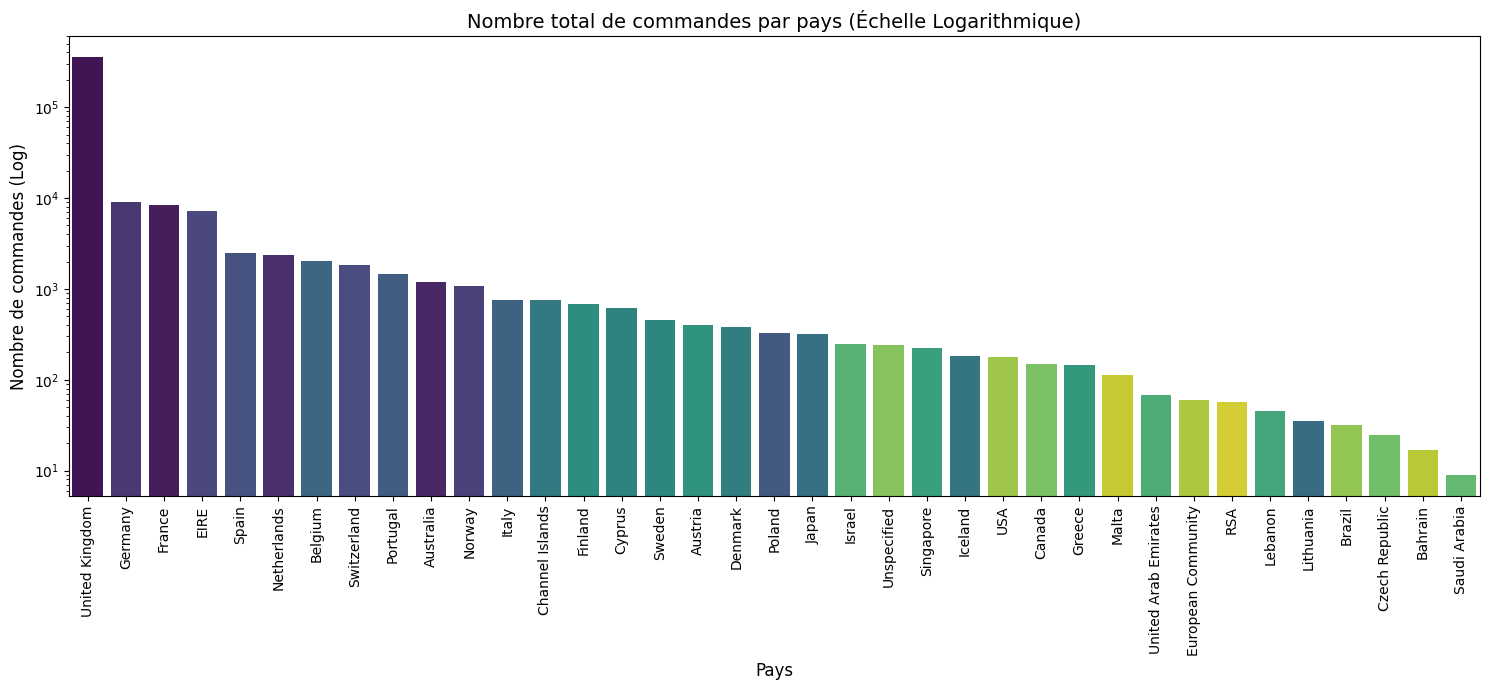

In [ ]:
# Histogramme

import matplotlib.pyplot as plt
import seaborn as sns

# Préparation de la figure
plt.figure(figsize=(15, 7))

# Création du graphique
# On ajoute 'hue' pour la couleur et 'legend=False' pour éviter le Warning
# 'order' permet de trier les pays du plus grand au plus petit
sns.countplot(
    data=df_clean,
    x='Country',
    hue='Country',
    palette='viridis',
    legend=False,
    order=df_clean['Country'].value_counts().index
)

# Correction de l'échelle (pour voir les pays hors UK)
plt.yscale('log')

# Habillage du graphique
plt.title("Nombre total de commandes par pays (Échelle Logarithmique)", fontsize=14)
plt.xlabel("Pays", fontsize=12)
plt.ylabel("Nombre de commandes (Log)", fontsize=12)

#Rotation des noms de pays pour qu'ils ne se chevauchent pas
plt.xticks(rotation=90)

#Ajustement automatique pour ne pas couper les labels
plt.tight_layout()

# Affichage du graphique
plt.show()

# Partie 4 : Prédiction & Recommandations clients

Dans cette section, nous allons exploiter les clusters RFM créés précédemment pour construire un modèle de classification supervisée. Les objectifs sont doubles :

  Dans un premier temps, prédire le segment (cluster) auquel appartient un nouveau client à partir de ses variables RFM.
  Ensuite, formuler des recommandations business personnalisées pour chaque segment afin d'aider l'entreprise à cibler ses clients de manière optimale.

Le pipeline complet suit les étapes suivantes :

  - Préparation des données (features X et cible y)
  - Séparation Train / Test (80 % / 20 %)
  - Entraînement de trois classifieurs : Random Forest, K-Nearest Neighbors et Régression Logistique
  - Évaluation des modèles (accuracy, rapport de classification, matrice de confusion)
  - Sélection du meilleur modèle
  - Recommandations business par segment


In [ ]:
# Toutes les bibliothèques pour les modèles
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression

# Les bibliothèques pour les métriques d'évaluation
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print("Toutes les bibliothèques ont bien été importées")

Toutes les bibliothèques ont bien été importées


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

scaled = scaler.fit_transform(rfm[["Recency","Frequency","Monetary"]])

# Préparation des données : features (X) et cible (y)

Pour entraîner un classifieur, on doit définir :

- X : la matrice des variables explicatives, ici on utilise les données RFM normalisées (scaled) plus haut. Il est essentielle de se servir des données normalisées (StandarScaler) pour que les algorithmes sensibles aux distances (KNN, Régression Logistique) ne soient pas biaisés par l'échelle des variables.
- Y : le vecteur cible, c'est-à-dire le numéro de cluster assigné à chaque client lors de la phase de clustering (colonne cluster du DataFrame rfm).

On va également afficher la répartition des classes pour vérifier que les clusters ne sont pas trop déséquilibrés, ce qui pourrait affecter l'apprentissage du modèle.

In [ ]:
# x contient nos variables RFM normalisées
X = scaled # array numpy de shape (n_clients,3)

# y contient le label du cluster pour chaque client
y = rfm["cluster"].values   # array numpy de shape (n_clients,)

# Vérification des dimensions
print("="*55)
print("Dimensens des données")
print("="*55)
print(f"  Nombre de clients  : {X.shape[0]:,}")
print(f"  Nombre de features : {X.shape[1]}  (Recency, Frequency, Monetary)")
print(f"  Nombre de classes  : {len(np.unique(y))}  (clusters 0, 1, 2)")

# Répartition des clusters
print()
print("="*55)
print("Répartitions des clusters (cible y)")
print("="*55)
cluster_counts = pd.Series(y).value_counts().sort_index()
for cluster_id, count in cluster_counts.items():
    pct = count / len(y) * 100
    print(f"  Cluster {cluster_id} : {count:>5,} clients  ({pct:.1f} %)")
print(f"Nombre de features : {X.shape[1]} (Recency, Frequency, Monetary)")

Dimensens des données
  Nombre de clients  : 4,346
  Nombre de features : 2  (Recency, Frequency, Monetary)
  Nombre de classes  : 3  (clusters 0, 1, 2)

Répartitions des clusters (cible y)
  Cluster 0 : 1,089 clients  (25.1 %)
  Cluster 1 : 3,231 clients  (74.3 %)
  Cluster 2 :    26 clients  (0.6 %)
Nombre de features : 2 (Recency, Frequency, Monetary)


In [ ]:
# from sklearn.preprocessing import StandardScaler

# scaler = StandardScaler()

# scaled = scaler.fit_transform(rfm[["Recency","Monetary"]])

In [ ]:
print(scaler.n_features_in_)

3


In [ ]:
# Séparation stratifiée Train/Test
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size    = 0.2,    # 20 % pour le test
    stratify     = y,      # conserver les proportions de clusters
    random_state = 42      # reproductibilité
)

# Vérification des tailles
print("="*55)
print("Split Train/Test")
print("="*55)
print(f"  Ensemble d'entraînement : {X_train.shape[0]:,} clients ({X_train.shape[0]/len(X)*100:.0f} %)")
print(f"  Ensemble de test        : {X_test.shape[0]:,}  clients ({X_test.shape[0]/len(X)*100:.0f} %)")

# Vérification de la stratification
print()
print("="*55)
print("Répartition des clusters dans chaque ensemble")
print("="*55)
for split_name, y_split in [("Train", y_train), ("Test ", y_test)]:
    counts = pd.Series(y_split).value_counts().sort_index()
    proportions = (counts / len(y_split) * 100).round(1)
    print(f"  {split_name} → " + "  |  ".join([f"Cluster {k}: {proportions[k]}%" for k in counts.index]))


Split Train/Test
  Ensemble d'entraînement : 3,476 clients (80 %)
  Ensemble de test        : 870  clients (20 %)

Répartition des clusters dans chaque ensemble
  Train → Cluster 0: 25.1%  |  Cluster 1: 74.3%  |  Cluster 2: 0.6%
  Test  → Cluster 0: 25.1%  |  Cluster 1: 74.4%  |  Cluster 2: 0.6%


# Entraînement des modèles de classification

Nous allons comparer trois algorithmes de classification afin de choisir le plus performant :

  - Random Forest (RandomForestClassifier) Ensemble de 100 arbres de décision entraînés sur des sous-échantillons aléatoires.

  - K-Nearest Neighbors (KNeighborsClassifier) Classifie un client en lui attribuant le cluster le plus fréquent parmi ses 5 voisins les plus proches dans l'espace RFM normalisé. Ce modèle est simple et intuitif, mais peut être lent sur de très grands datasets.

  - Régression Logistique (LogisticRegression) Modèle linéaire qui estime la probabilité d'appartenance à chaque cluster. Rapide et interprétable. On augmente max_iter pour garantir la convergence.



In [ ]:
# Définition des trois modèles
modeles = {
    "Random Forest" : RandomForestClassifier(n_estimators=100, random_state=42),
    "KNN (k=5)" : KNeighborsClassifier(n_neighbors=5),
    "Régression Logistique": LogisticRegression(max_iter=500, random_state=42),
}

# Entraînement de chaque modèle
print("="*55)
print("Entrainnement des modèles")
print("="*55)

resultats = {}   # dictionnaire pour stocker accuracy + prédictions

for nom, modele in modeles.items():
    # Entraînement sur les données d'apprentissage
    modele.fit(X_train, y_train)

    # Prédiction sur les données de test (jamais vues)
    y_pred = modele.predict(X_test)

    # Calcul de l'accuracy
    # Elle est calculé l'accuray ici car comme nous bouclons déjà sur 3 modèles,
    #autant le faire là, ceci nous éviteras de le faire encore plus tard.
    #Nous la stockons pour l'utiliser après pour le barplot de comparaison, les rapports de classification détaillés et les matrices de confusion
    acc = accuracy_score(y_test, y_pred)

    # Sauvegarde des résultats
    resultats[nom] = {"modele": modele, "y_pred": y_pred, "accuracy": acc}

    print(f" {nom:<25} → Accuracy : {acc*100:.2f} %")

print()
print("Tous les modèles sont bien entraînés.")

Entrainnement des modèles
 Random Forest             → Accuracy : 99.43 %
 KNN (k=5)                 → Accuracy : 99.66 %
 Régression Logistique     → Accuracy : 99.43 %

Tous les modèles sont bien entraînés.


# Comparaison des performances

L'accuracy (taux de bonne classification) est la première métrique que nous allons regarder. On va la visualiser sous forme de barplot pour comparer rapidement les trois modèles.


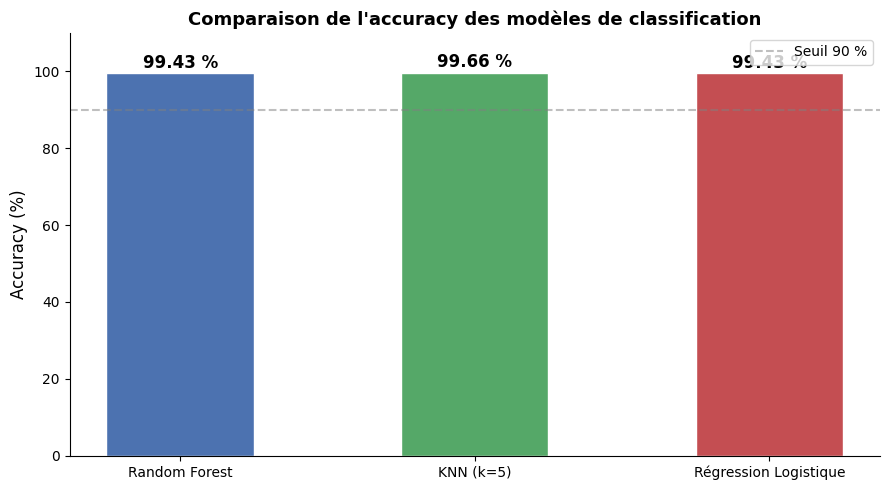

Tableau récapitulatif
               Modèle  Accuracy (%)
            KNN (k=5)         99.66
        Random Forest         99.43
Régression Logistique         99.43


In [ ]:
# Barplot de comparaison des accuracies
noms_modeles = list(resultats.keys())
accuracies   = [resultats[n]["accuracy"] * 100 for n in noms_modeles]
couleurs     = ["#4C72B0", "#55A868", "#C44E52"]

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(noms_modeles, accuracies, color=couleurs, edgecolor="white", width=0.5)

# Ajouter les valeurs au-dessus de chaque barre
for bar, acc in zip(bars, accuracies):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.3,
            f"{acc:.2f} %",
            ha="center", va="bottom", fontsize=12, fontweight="bold")

ax.set_ylim(0, 110)
ax.set_ylabel("Accuracy (%)", fontsize=12)
ax.set_title("Comparaison de l'accuracy des modèles de classification", fontsize=13, fontweight="bold")
ax.axhline(y=90, color="gray", linestyle="--", alpha=0.5, label="Seuil 90 %")
ax.legend()
sns.despine()
plt.tight_layout()
plt.show()

# Tableau récapitulatif
df_resultats = pd.DataFrame({
    "Modèle"      : noms_modeles,
    "Accuracy (%)" : [round(a, 2) for a in accuracies]
}).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)

print("="*40)
print("Tableau récapitulatif")
print("="*40)
print(df_resultats.to_string(index=False))

# Rapport de classification détaillé

Au-delà de l'accuracy globale, le rapport de classification nous donne pour chaque cluster :

  - Une précision : pour vérifier que parmi les clients prédits dans ce cluster, combien y appartiennent vraiment ?
  - Un rappel : dans les vrais membres du cluster, combien ont été correctement identifiés ?
  - Un F1-score : pour avoir une moyenne harmonique de la précision et du rappel (équilibre entre les deux)
  - Un support : connaitre le ombre de clients réels dans ce cluster dans l'ensemble de test

On affiche ce rapport pour chaque modèle.

In [ ]:
noms_clusters = {
    0: "Cluster 0 (Inactif)",
    1: "Cluster 1 (Réguliers)",
    2: "Cluster 2 (VIP)"
}

target_names = [noms_clusters[i] for i in sorted(noms_clusters.keys())]

for nom, res in resultats.items():
    print("="*65)
    print(f"Rapport de classification - {nom}")
    print("="*65)

    print(classification_report(
        y_test,
        res["y_pred"],
        target_names=target_names
    ))

Rapport de classification - Random Forest
                       precision    recall  f1-score   support

  Cluster 0 (Inactif)       0.99      1.00      0.99       218
Cluster 1 (Réguliers)       1.00      1.00      1.00       647
      Cluster 2 (VIP)       1.00      0.60      0.75         5

             accuracy                           0.99       870
            macro avg       0.99      0.87      0.91       870
         weighted avg       0.99      0.99      0.99       870

Rapport de classification - KNN (k=5)
                       precision    recall  f1-score   support

  Cluster 0 (Inactif)       0.99      1.00      1.00       218
Cluster 1 (Réguliers)       1.00      1.00      1.00       647
      Cluster 2 (VIP)       1.00      0.80      0.89         5

             accuracy                           1.00       870
            macro avg       1.00      0.93      0.96       870
         weighted avg       1.00      1.00      1.00       870

Rapport de classification - Régr

# Matrices de confusion

La matrice de confusion est une représentation visuelle des erreurs de classification :

  - Les lignes représentent les classes réelles (le vrai cluster du client).
  - Les colonnes représentent les classes prédites par le modèle.
  - La diagonale (en foncé) représente les clients correctement classifiés.
  - Les valeurs hors diagonale représentent les erreurs : un client du cluster i prédit dans le cluster j.

Plus la diagonale est dominante, meilleur est notre modèle.

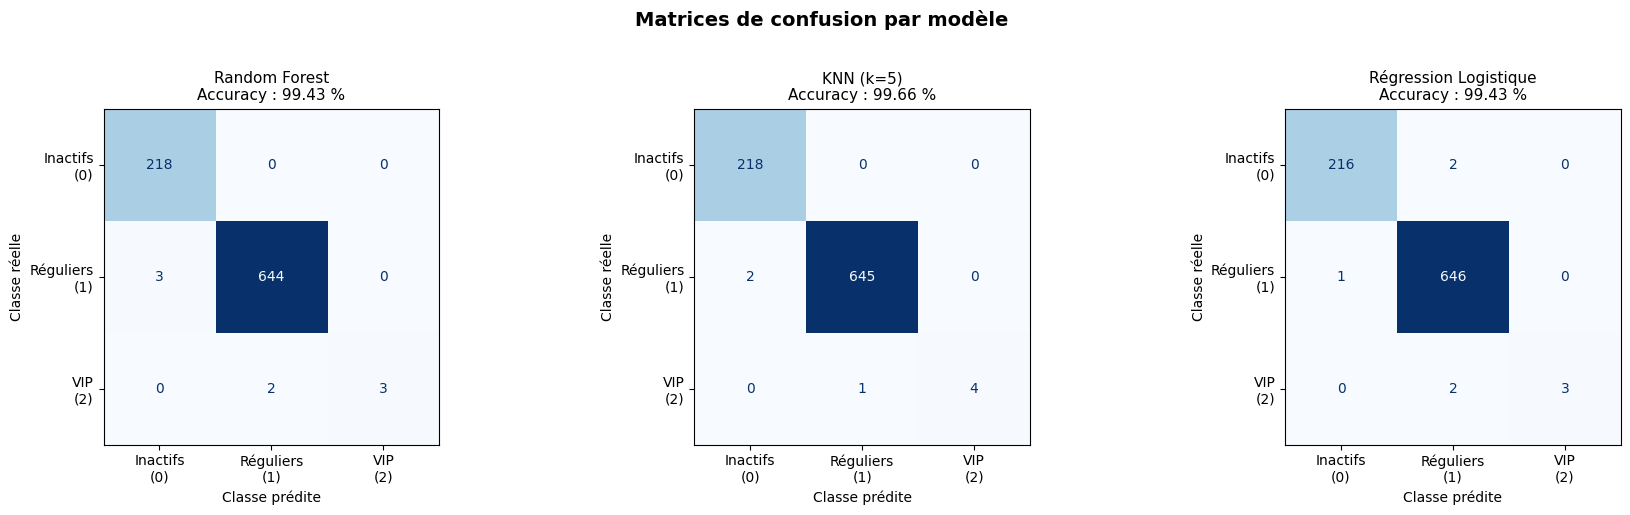

In [ ]:
# Affichage de notre matrice de confusion
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Matrices de confusion par modèle", fontsize=14, fontweight="bold", y=1.02)

labels_courts = ["Inactifs\n(0)", "Réguliers\n(1)", "VIP\n(2)"]

for ax, (nom, res) in zip(axes, resultats.items()):
    cm   = confusion_matrix(y_test, res["y_pred"])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels_courts)
    disp.plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{nom}\nAccuracy : {res['accuracy']*100:.2f} %", fontsize=11)
    ax.set_xlabel("Classe prédite", fontsize=10)
    ax.set_ylabel("Classe réelle", fontsize=10)

plt.tight_layout()
plt.show()

# Sélection du meilleur modèle

On sélectionne automatiquement le modèle ayant la meilleure accuracy sur l'ensemble de test. Ce modèle sera utilisé pour faire des prédictions sur de nouveaux clients.

Cross-Validation — Évaluation robuste des modèles

Un simple split Train/Test dépend du hasard du découpage : selon les clients qui tombent dans le test, l'accuracy peut varier. La cross-validation K-Fold résout ce problème en répétant l'évaluation sur k découpages différents et en moyennant les scores.

On utilise Stratified K-Fold (variante du K-Fold) qui garantit que la proportion de chaque cluster est conservée dans chaque fold — indispensable ici car le Cluster 2 (VIP) est peu nombreux.

In [ ]:
# Import des outils de cross-validation
from sklearn.model_selection import StratifiedKFold, cross_validate
import warnings
warnings.filterwarnings("ignore")   # masquer les avertissements de convergence

# Paramètres de la cross-validation
N_FOLDS = 5   # nombre de folds

# StratifiedKFold : conserve les proportions de clusters dans chaque fold
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

# Cross-validation sur les 3 modèles
print("="*60)
print("Cross-Validation (Stratified K-Fold, k=5)")
print("="*60)

cv_resultats = {}   # stockage des scores par modèle

for nom, modele in modeles.items():

    # cross_validate retourne les scores pour chaque fold
    # scoring : on évalue accuracy ET f1_macro en même temps
    scores = cross_validate(
        modele, X, y,
        cv      = skf,
        scoring = ["accuracy", "f1_macro"],
        n_jobs  = -1    # utiliser tous les cœurs disponibles
    )

    # Récupération des scores par fold
    acc_folds = scores["test_accuracy"]
    f1_folds  = scores["test_f1_macro"]

    # Stockage pour la visualisation suivante
    cv_resultats[nom] = {
        "acc_folds" : acc_folds,
        "f1_folds"  : f1_folds,
        "acc_mean"  : acc_folds.mean(),
        "acc_std"   : acc_folds.std(),
        "f1_mean"   : f1_folds.mean(),
        "f1_std"    : f1_folds.std(),
    }

    print(f"\n  {nom}")
    print(f"  {'─'*45}")
    print(f"  Accuracy  par fold : {[f'{a*100:.2f}%' for a in acc_folds]}")
    print(f"  Accuracy  moyenne  : {acc_folds.mean()*100:.2f} % (± {acc_folds.std()*100:.2f} %)")
    print(f"  F1-macro  moyenne  : {f1_folds.mean()*100:.2f} % (± {f1_folds.std()*100:.2f} %)")

Cross-Validation (Stratified K-Fold, k=5)

  Random Forest
  ─────────────────────────────────────────────
  Accuracy  par fold : ['99.54%', '99.31%', '99.65%', '99.31%', '99.42%']
  Accuracy  moyenne  : 99.45 % (± 0.13 %)
  F1-macro  moyenne  : 94.84 % (± 4.48 %)

  KNN (k=5)
  ─────────────────────────────────────────────
  Accuracy  par fold : ['99.20%', '99.31%', '99.42%', '99.31%', '99.54%']
  Accuracy  moyenne  : 99.36 % (± 0.12 %)
  F1-macro  moyenne  : 94.31 % (± 4.75 %)

  Régression Logistique
  ─────────────────────────────────────────────
  Accuracy  par fold : ['98.97%', '99.31%', '99.31%', '99.42%', '99.31%']
  Accuracy  moyenne  : 99.26 % (± 0.16 %)
  F1-macro  moyenne  : 92.75 % (± 5.54 %)


Visualisation des scores par fold

Le graphique ci-dessous montre pour chaque modèle :

  - La barre : l'accuracy moyenne sur les 5 folds
  - Les barres d'erreur : l'écart-type (± std) — plus elles sont petites, plus le modèle est stable
  - Les points : le score exact de chaque fold individuel


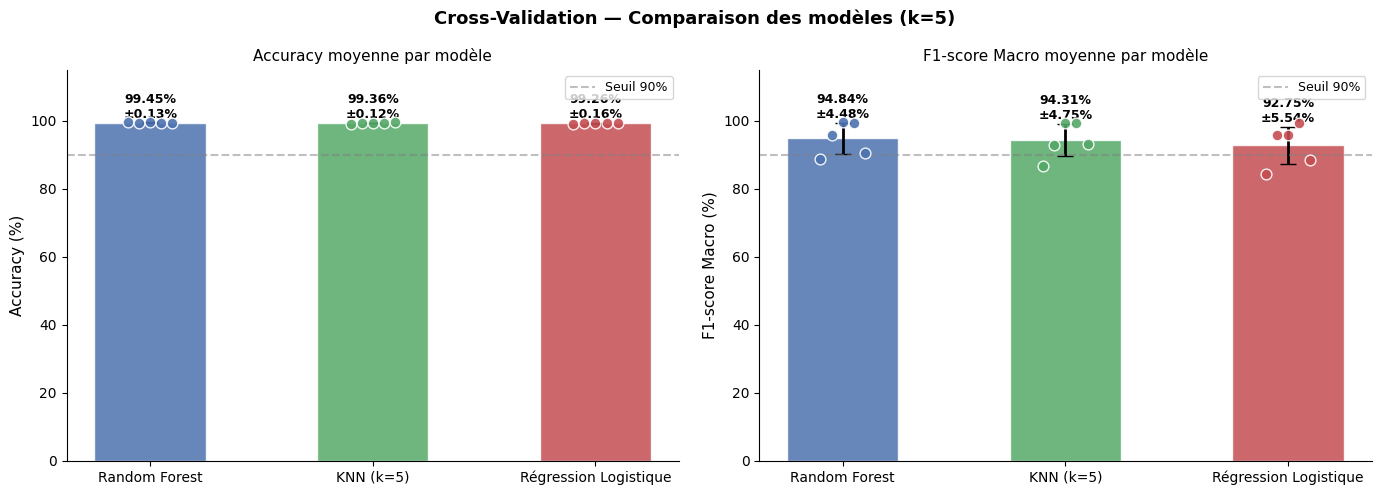

In [ ]:
# Visualisation : accuracy moyenne + écart-type par modèle
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Cross-Validation — Comparaison des modèles (k=5)", fontsize=13, fontweight="bold")

noms   = list(cv_resultats.keys())
colors = ["#4C72B0", "#55A868", "#C44E52"]

for ax, metric, label in zip(axes, ["acc", "f1"], ["Accuracy", "F1-score Macro"]):

    means = [cv_resultats[n][f"{metric}_mean"] * 100 for n in noms]
    stds  = [cv_resultats[n][f"{metric}_std"]  * 100 for n in noms]
    folds = [cv_resultats[n][f"{metric}_folds"] * 100 for n in noms]

    # Barres avec écart-type
    bars = ax.bar(noms, means, color=colors, edgecolor="white",
                  width=0.5, yerr=stds, capsize=6, alpha=0.85,
                  error_kw={"elinewidth": 2, "ecolor": "black"})

    # Points individuels par fold (jitter léger)
    for i, (fold_scores, color) in enumerate(zip(folds, colors)):
        x_jitter = [i + (j - N_FOLDS//2) * 0.05 for j in range(len(fold_scores))]
        ax.scatter(x_jitter, fold_scores, color=color, edgecolor="white",
                   s=60, zorder=5, alpha=0.9)

    # Valeurs au-dessus des barres
    for bar, mean, std in zip(bars, means, stds):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + std + 0.5,
                f"{mean:.2f}%\n±{std:.2f}%",
                ha="center", va="bottom", fontsize=9, fontweight="bold")

    ax.set_ylim(0, 115)
    ax.set_ylabel(f"{label} (%)", fontsize=11)
    ax.set_title(f"{label} moyenne par modèle", fontsize=11)
    ax.axhline(y=90, color="gray", linestyle="--", alpha=0.5, label="Seuil 90%")
    ax.legend(fontsize=9)
    sns.despine()

plt.tight_layout()
plt.show()

# Tableau récapitulatif — Cross-Validation vs Train/Test

On compare ici les accuracies obtenues avec les deux méthodes d'évaluation. Si les scores sont proches, cela confirme que notre modèle est stable et que le split initial n'était pas biaisé.

In [ ]:
# Tableau comparatif CV vs Train/Test
lignes = []
for nom in noms:
    lignes.append({
        "Modèle"                  : nom,
        "Accuracy Train/Test (%)" : round(resultats[nom]["accuracy"] * 100, 2),
        "Accuracy CV moyenne (%)" : round(cv_resultats[nom]["acc_mean"] * 100, 2),
        "Écart-type CV (%)"       : round(cv_resultats[nom]["acc_std"] * 100, 2),
        "F1-macro CV (%)"         : round(cv_resultats[nom]["f1_mean"] * 100, 2),
    })

df_cv = pd.DataFrame(lignes).sort_values("Accuracy CV moyenne (%)", ascending=False).reset_index(drop=True)

print("="*75)
print("Tableau comparatif — CROSS-VALIDATION vs TRAIN/TEST")
print("="*75)
print(df_cv.to_string(index=False))
print()

# Identifier le meilleur modèle selon la CV
meilleur_cv = df_cv.iloc[0]["Modèle"]
print(f"Meilleur modèle selon la cross-validation : {meilleur_cv}")
print()
print("Un écart-type faible (< 2%) indique un modèle stable et fiable.")

Tableau comparatif — CROSS-VALIDATION vs TRAIN/TEST
               Modèle  Accuracy Train/Test (%)  Accuracy CV moyenne (%)  Écart-type CV (%)  F1-macro CV (%)
        Random Forest                    99.43                    99.45               0.13            94.84
            KNN (k=5)                    99.66                    99.36               0.12            94.31
Régression Logistique                    99.43                    99.26               0.16            92.75

Meilleur modèle selon la cross-validation : Random Forest

Un écart-type faible (< 2%) indique un modèle stable et fiable.


In [ ]:
# Sélection automatique du meilleur modèle
meilleur_nom    = max(resultats, key=lambda n: resultats[n]["accuracy"])
meilleur_modele = resultats[meilleur_nom]["modele"]
meilleure_acc   = resultats[meilleur_nom]["accuracy"]

print("="*55)
print("Meilleur modèle sélectionné")
print("="*55)
print(f"  Modèle   : {meilleur_nom}")
print(f"  Accuracy : {meilleure_acc*100:.2f} %")
print()
print("Ce modèle sera utilisé pour prédire le segment")
print("d'appartenance de nouveaux clients.")

Meilleur modèle sélectionné
  Modèle   : KNN (k=5)
  Accuracy : 99.66 %

Ce modèle sera utilisé pour prédire le segment
d'appartenance de nouveaux clients.


# Importance des variables RFM (Random Forest)

Même si la cross-validation a désigné le KNN comme meilleur modèle sur notre jeu de données, le Random Forest reste très utile ici pour une raison spécifique : il est le seul de nos trois modèles à fournir un score d'importance des features.

Ce score indique la contribution de chaque variable RFM à la décision de classification.
Un score élevé signifie que la variable est très discriminante pour distinguer les clusters.
Cela nous donne une information précieuse sur ce qui différencie le plus nos segments de clients, et peut orienter les décisions marketing : si la Recency est la variable la plus importante, l'entreprise devra par exemple prioriser la réactivation des clients inactifs.

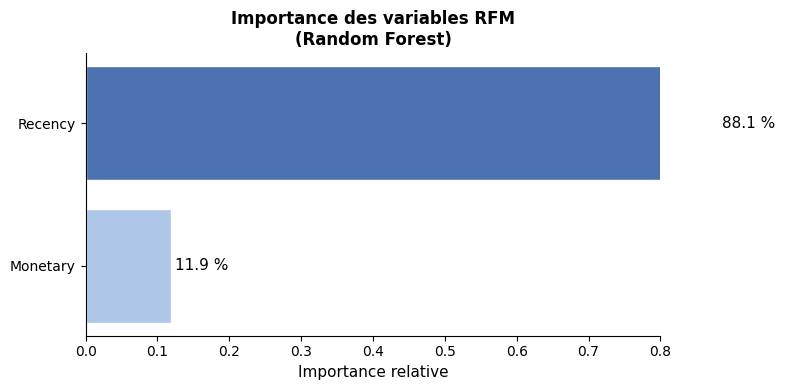

Importance des variables RFM
  Recency      : 88.06 %
  Monetary     : 11.94 %


In [ ]:
# Importance des features — Random Forest
rf_modele    = resultats["Random Forest"]["modele"]
importances  = rf_modele.feature_importances_
feature_names = ["Recency", "Monetary"] #

# Créer un DataFrame trié par importance décroissante
df_importance = pd.DataFrame({
    "Feature"   : feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=True)   # ascending=True pour barh

# Visualisation
fig, ax = plt.subplots(figsize=(8, 4))
colors = ["#4C72B0" if imp == df_importance["Importance"].max() else "#AEC6E8"
          for imp in df_importance["Importance"]]

bars = ax.barh(df_importance["Feature"], df_importance["Importance"],
               color=colors, edgecolor="white")

for bar, imp in zip(bars, df_importance["Importance"]):
    ax.text(bar.get_width() + 0.005, bar.get_y() + bar.get_height()/2,
            f"{imp*100:.1f} %", va="center", fontsize=11)

ax.set_xlim(0, 0.8)
ax.set_xlabel("Importance relative", fontsize=11)
ax.set_title("Importance des variables RFM\n(Random Forest)", fontsize=12, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.show()

# Affichage textuel
print("="*45)
print("Importance des variables RFM")
print("="*45)
for _, row in df_importance.sort_values("Importance", ascending=False).iterrows():
    print(f"  {row['Feature']:<12} : {row['Importance']*100:.2f} %")

In [ ]:
print("Scaler attend :", scaler.n_features_in_)
if hasattr(scaler, "feature_names_in_"):
    print("Colonnes attendues :", scaler.feature_names_in_)

Scaler attend : 3
Colonnes attendues : ['Recency' 'Frequency' 'Monetary']


# Prédiction sur un nouveau client

Pour illustrer l'utilisation pratique du modèle, on simule l'arrivée d'un nouveau client dont on connaît les variables RFM. Le modèle prédit automatiquement son segment d'appartenance.

Les données du nouveau client sont normalisées avec le même StandardScaler utilisé lors de l'entraînement, sinon la prédiction serait incorrecte.


In [ ]:
# Définition des 3 profils types à tester
profils = [
    {"nom": "Client récent et actif", "Recency": 10,  "Frequency": 6,  "Monetary": 1500.0},
    {"nom": "Client inactif",         "Recency": 200, "Frequency": 2,  "Monetary": 300.0},
    {"nom": "Gros acheteur",          "Recency": 5,   "Frequency": 50, "Monetary": 60000.0},
]

noms_clusters_dict = {
    0: "Clients Inactifs 🔴",
    1: "Clients Réguliers 🟡",
    2: "Clients VIP 🟢"
}

print("="*65)
print("Prédiction pour 3 nouveaux clients")
print("="*65)

for profil in profils:
    # Création du DataFrame client
    nouveau_client = pd.DataFrame({
        "Recency"  : [profil["Recency"]],
        "Frequency": [profil["Frequency"]],
        "Monetary" : [profil["Monetary"]]
    })

    # Normalisation OBLIGATOIRE avec le même scaler qu'à l'entraînement
    nouveau_client_scaled = scaler.transform(nouveau_client)

    # Sélectionner uniquement les features sur lesquelles le modèle a été entraîné (Recency et Monetary)
    # X = scaled[:, [0,2]] donc nous utilisons les mêmes indices ici
    nouveau_client_for_prediction = nouveau_client_scaled[:, [0, 2]]

    # Prédiction du cluster
    cluster_predit = meilleur_modele.predict(nouveau_client_for_prediction)[0]

    print()
    print(f"  {profil['nom']}")
    print(f"  {'─'*45}")
    print(f"  Recency   : {profil['Recency']} jours depuis la dernière commande")
    print(f"  Frequency : {profil['Frequency']} commandes passées")
    print(f"  Monetary  : {profil['Monetary']:,.0f} £ dépensés")
    print(f"  ➜ Segment prédit : Cluster {cluster_predit} — {noms_clusters_dict[cluster_predit]}")

    # Probabilités d'appartenance
    if hasattr(meilleur_modele, "predict_proba"):
        proba = meilleur_modele.predict_proba(nouveau_client_for_prediction)[0]
        print(f"  Probabilités : " + "  |  ".join(
            [f"Cluster {j}: {p*100:.1f}%" for j, p in enumerate(proba)]
        ))

print()
print("="*65)
print("Cas d'usage business")
print("="*65)
print("  Après 3 mois d'activité d'un nouveau client, l'entreprise")
print("  peut calculer ses variables RFM et prédire automatiquement")
print("  son segment pour déclencher la campagne marketing adaptée :")
print()
print("  Inactif   🔴 → Campagne de réactivation immédiate")
print("  Régulier  🟡 → Programme de fidélité + upselling")
print("  VIP       🟢 → Accès programme premium exclusif")

Prédiction pour 3 nouveaux clients

  Client récent et actif
  ─────────────────────────────────────────────
  Recency   : 10 jours depuis la dernière commande
  Frequency : 6 commandes passées
  Monetary  : 1,500 £ dépensés
  ➜ Segment prédit : Cluster 1 — Clients Réguliers 🟡
  Probabilités : Cluster 0: 0.0%  |  Cluster 1: 100.0%  |  Cluster 2: 0.0%

  Client inactif
  ─────────────────────────────────────────────
  Recency   : 200 jours depuis la dernière commande
  Frequency : 2 commandes passées
  Monetary  : 300 £ dépensés
  ➜ Segment prédit : Cluster 0 — Clients Inactifs 🔴
  Probabilités : Cluster 0: 100.0%  |  Cluster 1: 0.0%  |  Cluster 2: 0.0%

  Gros acheteur
  ─────────────────────────────────────────────
  Recency   : 5 jours depuis la dernière commande
  Frequency : 50 commandes passées
  Monetary  : 60,000 £ dépensés
  ➜ Segment prédit : Cluster 2 — Clients VIP 🟢
  Probabilités : Cluster 0: 0.0%  |  Cluster 1: 0.0%  |  Cluster 2: 100.0%

Cas d'usage business
  Après 3 moi

# Recommandation business pour chaque segment

Sur la base des profils que nous avons obtenus précédemment, nous sommes en mesure de pouvoir faire des recommandations marketing ciblées pour chaque segment identifié. Le but est de calibrer parfaitement les actions commerciales pour chaque groupe de clients.

In [ ]:
# Résumé visuel des recommandations par cluster
recommandations = {
    0: {
        "label"   : "Clients Inactifs ",
        "profil"  : "Recency élevée | Fréquence faible | Montant faible",
        "actions" : [
            "Campagne email de réactivation + code promo",
            "Presentation des nouveaux produits + code promo"
            "Offres temporaires",
            "Sondage satisfaction",
            "Identifier les clients perdus (> 1 an sans commande)",
        ]
    },
    1: {
        "label"   : "Clients Réguliers ",
        "profil"  : "Recency modérée | Fréquence moyenne | Montant moyen",
        "actions" : [
            "Programme de fidélité avec points",
            "Cross-selling & Up-selling",
            "Offres personnalisées (anniversaire, etc.)",
            "Newsletter ciblée sur leurs habitudes",
        ]
    },
    2: {
        "label"   : "Clients VIP ",
        "profil"  : "Recency faible | Fréquence élevée | Montant élevé",
        "actions" : [
            "Programme VIP : accès anticipé, ventes privées",
            "Gestionnaire de compte dédié",
            "Surveillance du désengagement en temps réel",
        ]
    },
}

print("="*65)
print("Recommandation marketing pour chaque segement")
print("="*65)

for cluster_id, info in recommandations.items():
    n_clients = (rfm["cluster"] == cluster_id).sum()
    pct       = n_clients / len(rfm) * 100
    print()
    print(f"  CLUSTER {cluster_id} — {info['label']}")
    print(f"  Profil   : {info['profil']}")
    print(f"  Taille   : {n_clients:,} clients ({pct:.1f} % du portefeuille)")
    print(f"  Actions :")
    for action in info["actions"]:
        print(f"    → {action}")
    print("-"*65)

Recommandation marketing pour chaque segement

  CLUSTER 0 — Clients Inactifs 
  Profil   : Recency élevée | Fréquence faible | Montant faible
  Taille   : 1,089 clients (25.1 % du portefeuille)
  Actions :
    → Campagne email de réactivation + code promo
    → Presentation des nouveaux produits + code promoOffres temporaires
    → Sondage satisfaction
    → Identifier les clients perdus (> 1 an sans commande)
-----------------------------------------------------------------

  CLUSTER 1 — Clients Réguliers 
  Profil   : Recency modérée | Fréquence moyenne | Montant moyen
  Taille   : 3,231 clients (74.3 % du portefeuille)
  Actions :
    → Programme de fidélité avec points
    → Cross-selling & Up-selling
    → Offres personnalisées (anniversaire, etc.)
    → Newsletter ciblée sur leurs habitudes
-----------------------------------------------------------------

  CLUSTER 2 — Clients VIP 
  Profil   : Recency faible | Fréquence élevée | Montant élevé
  Taille   : 26 clients (0.6 % du

# Pour aller plus loin : VotingClassifier (Ensemble Learning)

Maintenant que nous avons comparé les 3 modèles individuellement, on peut aller plus loin en les combinant. C'est ce qu'on appelle l'Ensemble Learning : l'idée est que plusieurs modèles qui collaborent font moins d'erreurs qu'un seul modèle seul. C'est le principe du vote majoritaire

Pour chaque client, les 3 modèles donnent chacun une prédiction. Le VotingClassifier retient la réponse majoritaire :

Prenons un exemple, le client X :

  - Le Random Forest le classe dans le Cluster 1
  - Le KNN le classe Cluster 1
  - Et la régression Logistique dans le Cluster 0

Avec cette methode d'ensemble learning, le client sera classé dans le cluster 1 (2 voix contre 1).

Si un modèle se trompe mais que les deux autres ont raison, l'erreur est corrigée automatiquement par le vote. C'est le principe du voting='soft' vs voting='hard'

Mode Fonctionnement Avantage

Le voting 'hard' c'est le fait de voter à la majorité, c'est plutôt simple. Alors que le voting 'soft', on fait la moyenne des probabilités de chaque modèle. C'est plus précis car on utilise la confiance de chaque modèle

Ici on va opter pour le 'soft' car nos 3 modèles supportent tous predict_proba().

In [ ]:
# Import du VotingClassifier
from sklearn.ensemble import VotingClassifier

# Construction du VotingClassifier
# On réutilise les mêmes modèles déjà définis, avec voting='soft'
voting_clf = VotingClassifier(
    estimators=[
        ("Random Forest",         RandomForestClassifier(n_estimators=100, random_state=42)),
        ("KNN",                   KNeighborsClassifier(n_neighbors=5)),
        ("Régression Logistique", LogisticRegression(max_iter=500, random_state=42)),
    ],
    voting="soft"   # utilise les probabilités plutôt qu'un simple vote majoritaire
)

# Entraînement sur le train set
voting_clf.fit(X_train, y_train)

# Prédiction sur le test set
y_pred_voting = voting_clf.predict(X_test)

#  Accuracy du VotingClassifier
acc_voting = accuracy_score(y_test, y_pred_voting)

print("="*55)
print(" Voting classifier — Résultats")
print("="*55)
print(f"  Accuracy : {acc_voting*100:.2f} %")
print()

# Comparaison avec les modèles individuels
print("="*55)
print("Comparaison : Modèles individuels vs VotingClassifier")
print("="*55)
for nom, res in resultats.items():
    diff = (acc_voting - res["accuracy"]) * 100
    signe = "+" if diff >= 0 else ""
    print(f"  {nom:<25} : {res['accuracy']*100:.2f} %")
print(f"  {'VotingClassifier':<25} : {acc_voting*100:.2f} %  ← combinaison des 3")

 Voting classifier — Résultats
  Accuracy : 99.54 %

Comparaison : Modèles individuels vs VotingClassifier
  Random Forest             : 99.43 %
  KNN (k=5)                 : 99.66 %
  Régression Logistique     : 99.43 %
  VotingClassifier          : 99.54 %  ← combinaison des 3


# Rapport de classification et matrice de confusion du VotingClassifier

On vérifie maintenant que la combinaison des modèles est homogène sur tous les clusters, notamment sur les VIP (Cluster 2) qui sont les plus difficiles à classifier correctement.

Rapport de classification — VotingClassifier
                       precision    recall  f1-score   support

 Cluster 0 (Inactifs)       0.99      1.00      1.00       218
Cluster 1 (Réguliers)       1.00      1.00      1.00       647
      Cluster 2 (VIP)       1.00      0.60      0.75         5

             accuracy                           1.00       870
            macro avg       1.00      0.87      0.91       870
         weighted avg       1.00      1.00      1.00       870



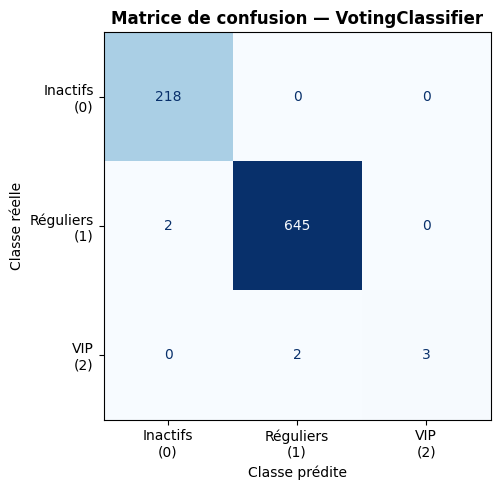

In [ ]:
# Rapport de classification détaillé
noms_clusters = {0: "Cluster 0 (Inactifs)", 1: "Cluster 1 (Réguliers)", 2: "Cluster 2 (VIP)"}
target_names  = [noms_clusters[i] for i in sorted(noms_clusters.keys())]

print("="*65)
print("Rapport de classification — VotingClassifier")
print("="*65)
print(classification_report(y_test, y_pred_voting, target_names=target_names))

# Matrice de confusion
fig, ax = plt.subplots(figsize=(6, 5))

cm   = confusion_matrix(y_test, y_pred_voting)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Inactifs\n(0)", "Réguliers\n(1)", "VIP\n(2)"])
disp.plot(ax=ax, colorbar=False, cmap="Blues")

ax.set_title("Matrice de confusion — VotingClassifier", fontsize=12, fontweight="bold")
ax.set_xlabel("Classe prédite", fontsize=10)
ax.set_ylabel("Classe réelle", fontsize=10)
plt.tight_layout()
plt.show()

In [ ]:
# Cross-validation du VotingClassifier
scores_voting = cross_validate(
    VotingClassifier(
        estimators=[
            ("rf",  RandomForestClassifier(n_estimators=100, random_state=42)),
            ("knn", KNeighborsClassifier(n_neighbors=5)),
            ("lr",  LogisticRegression(max_iter=500, random_state=42)),
        ],
        voting="soft"
    ),
    X, y,
    cv      = skf,
    scoring = ["accuracy", "f1_macro"],
    n_jobs  = -1
)

acc_cv_voting = scores_voting["test_accuracy"].mean()
f1_cv_voting  = scores_voting["test_f1_macro"].mean()
std_cv_voting = scores_voting["test_accuracy"].std()

print("="*60)
print("Coss Validation — VotingClassifier (k=5)")
print("="*60)
print(f"  Accuracy  par fold : {[f'{a*100:.2f}%' for a in scores_voting['test_accuracy']]}")
print(f"  Accuracy  moyenne  : {acc_cv_voting*100:.2f} % (± {std_cv_voting*100:.2f} %)")
print(f"  F1-macro  moyenne  : {f1_cv_voting*100:.2f} %")
print()

# Tableau final comparatif complet
print("="*75)
print("Tableau final — Tous les modèles + VotingClassifier")
print("="*75)

lignes_finales = []
for nom in cv_resultats:
    lignes_finales.append({
        "Modèle"             : nom,
        "Accuracy CV (%)"    : round(cv_resultats[nom]["acc_mean"] * 100, 2),
        "Écart-type (%)"     : round(cv_resultats[nom]["acc_std"]  * 100, 2),
        "F1-macro CV (%)"    : round(cv_resultats[nom]["f1_mean"]  * 100, 2),
    })

lignes_finales.append({
    "Modèle"          : "VotingClassifier",
    "Accuracy CV (%)" : round(acc_cv_voting * 100, 2),
    "Écart-type (%)"  : round(std_cv_voting * 100, 2),
    "F1-macro CV (%)" : round(f1_cv_voting  * 100, 2),
})

df_final = pd.DataFrame(lignes_finales).sort_values("Accuracy CV (%)", ascending=False).reset_index(drop=True)
print(df_final.to_string(index=False))

Coss Validation — VotingClassifier (k=5)
  Accuracy  par fold : ['99.20%', '99.31%', '99.65%', '99.31%', '99.54%']
  Accuracy  moyenne  : 99.40 % (± 0.17 %)
  F1-macro  moyenne  : 94.48 %

Tableau final — Tous les modèles + VotingClassifier
               Modèle  Accuracy CV (%)  Écart-type (%)  F1-macro CV (%)
        Random Forest            99.45            0.13            94.84
     VotingClassifier            99.40            0.17            94.48
            KNN (k=5)            99.36            0.12            94.31
Régression Logistique            99.26            0.16            92.75


Conclusion sur le VotingClassifier

Le tableau final permet de conclure objectivement :

  - Si le VotingClassifier a la meilleure accuracy et le plus faible écart-type → c'est lui qu'on recommande en production car il est à la fois le plus précis et le plus stable.
  - Si un modèle individuel fait jeu égal → le VotingClassifier n'apporte pas de gain significatif, mais il reste pertinent car il est moins sensible aux erreurs d'un seul modèle.
